# Exploration des données climatiques ERA5-Land (Algérie, 2015-2026)

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 30)

BASE = "/content/drive/MyDrive/data mining"
VARS = ["t2m", "d2m", "slhf", "ssr", "str", "sshf", "ro", "e", "u10", "v10", "sp", "tp"]

**Unités des variables** : t2m et d2m en °C ; ssr, str, sshf et slhf en J/m² par jour (flux accumulés, moyenne journalière du mois) ; e, tp et ro en mm par jour ; u10 et v10 en m/s ; sp en hPa.

## 1. Chargement des données

In [3]:
df = pd.read_parquet(f"{BASE}/era5_land_algeria_2x2_tidy.parquet")
df.head()

,cell_id,latitude,longitude,time,year,month,t2m,d2m,slhf,ssr,str,sshf,ro,e,u10,v10,sp,tp
0,0,18.95,3.35,2015-01-01,2015,1,16.053375,-7.532074,-56683.0,11383417.0,-9657388.0,-1886500.0,0.000000,-0.022666,-3.543621,-2.430153,963.178772,0.001218
1,0,18.95,3.35,2015-02-01,2015,2,21.763580,-6.394379,-185121.0,12895457.0,-10289442.0,-2418422.0,0.000287,-0.074025,-1.456465,-1.673329,958.395630,0.069442
2,0,18.95,3.35,2015-03-01,2015,3,24.019196,-3.503754,-119632.0,13892477.0,-10270548.0,-3387453.0,0.000171,-0.047837,-2.208664,-2.066267,957.931274,0.042050
3,0,18.95,3.35,2015-04-01,2015,4,27.534332,-10.967133,-142215.0,16948670.0,-12807040.0,-3806034.0,0.000000,-0.056868,-3.519528,-1.297863,958.647522,0.001171
4,0,18.95,3.35,2015-05-01,2015,5,33.414703,-3.737396,-197606.0,17073860.0,-12867167.0,-3741044.0,0.000000,-0.079017,-1.999554,-0.394081,955.312500,0.000851


## 2. Structure du jeu de données

In [4]:
print("Dimensions :", df.shape)
print("Période :", df["time"].min(), "->", df["time"].max())
print("Nombre de cellules :", df["cell_id"].nunique())
print("Nombre de mois :", df["time"].nunique())
print("Années :", sorted(df["year"].unique()))
df.info()

Dimensions : (764925, 18)
Période : 2015-01-01 00:00:00 -> 2026-09-01 00:00:00
Nombre de cellules : 5425
Nombre de mois : 141
Années : [np.int32(2015), np.int32(2016), np.int32(2017), np.int32(2018), np.int32(2019), np.int32(2020), np.int32(2021), np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025), np.int32(2026)]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 764925 entries, 0 to 764924
Data columns (total 18 columns):
 #   Column     Non-Null Count   Dtype         
---  ------     --------------   -----         
 0   cell_id    764925 non-null  int64         
 1   latitude   764925 non-null  float64       
 2   longitude  764925 non-null  float64       
 3   time       764925 non-null  datetime64[ns]
 4   year       764925 non-null  int32         
 5   month      764925 non-null  int32         
 6   t2m        764925 non-null  float32       
 7   d2m        764925 non-null  float32       
 8   slhf       764925 non-null  float32       
 9   ssr        764925 non-null  

In [5]:
mois_par_annee = df.groupby("year")["month"].nunique()
mois_par_annee

,month
year,
2015,12
2016,12
2017,12
2018,12
2019,12
2020,12
2021,12
2022,12
2023,12


In [6]:
df["region"] = pd.cut(df["latitude"], bins=[0, 26, 33, 45], labels=["Sud", "Centre", "Nord"])
echantillon = df.sample(n=min(200000, len(df)), random_state=42)
df["region"].value_counts()

,count
region,
Centre,379572
Sud,261273
Nord,124080


**Interprétation**

Le jeu de données contient 764925 lignes, soit 5425 cellules sur 141 mois (5425 × 141 = 764925, le panel est donc complet), de janvier 2015 à septembre 2026. Les années 2015 à 2025 sont complètes alors que 2026 ne compte que 9 mois (octobre à décembre manquent), ce qui faussera toute comparaison entre années qui n'en tient pas compte. Toutes les variables sont numériques donc aucun encodage n'est nécessaire (la colonne region créée ici sert seulement à l'exploration).

Le découpage par latitude donne 2692 cellules au Centre (50 pour cent), 1853 au Sud (34 pour cent) et 880 au Nord (16 pour cent), le Nord est donc nettement minoritaire, ce qui est à garder en tête pour le clustering et pour toute évaluation par région. Les seuils de 26° et 33° sont des coupures arbitraires en latitude, pas des frontières climatiques.

## 3. Valeurs manquantes, doublons et valeurs uniques

In [7]:
manquantes = pd.DataFrame({"nb": df.isna().sum(), "pourcentage": df.isna().mean() * 100})
manquantes

,nb,pourcentage
cell_id,0,0.0
latitude,0,0.0
longitude,0,0.0
time,0,0.0
year,0,0.0
month,0,0.0
t2m,0,0.0
d2m,0,0.0
slhf,0,0.0
ssr,0,0.0


In [8]:
print("Doublons (cellule, mois) :", df.duplicated(subset=["cell_id", "time"]).sum())
print("Lignes dupliquées :", df.duplicated().sum())

Doublons (cellule, mois) : 0
Lignes dupliquées : 0


In [ ]:
(df[VARS] == 0).sum()

,0
t2m,0
d2m,0
slhf,0
ssr,0
str,0
sshf,0
ro,148642
e,0
u10,0
v10,0


In [9]:
df.nunique()

,0
cell_id,5425
latitude,91
longitude,104
time,141
year,12
month,12
t2m,142509
d2m,110177
slhf,558713
ssr,737777


**Interprétation**

Il n'y a aucune valeur manquante et aucun doublon, donc les données sont complètes. Seule la variable ro vaut zéro, dans environ 19 pour cent des lignes (148642), ce n'est pas une erreur car il n'y a simplement pas de ruissellement dans les zones sèches, ce sont de vrais zéros et non des valeurs manquantes codées. Aucune autre variable ne vaut jamais zéro.

Le tableau des valeurs uniques montre une grille de 91 latitudes et 104 longitudes, soit 9464 points possibles, mais seulement 5425 cellules (environ 57 pour cent), car seule la partie située à l'intérieur des frontières de l'Algérie est conservée. Les variables physiques sont continues avec de très nombreuses valeurs distinctes, seuls month (12 valeurs), year (12 valeurs) et region (3 valeurs) sont de nature discrète.

## 4. Statistiques descriptives

In [10]:
df[VARS].describe().T

,count,mean,std,min,25%,50%,75%,max
t2m,764925.0,2.389549e+01,8.748615e+00,2.750549e-01,1.640958e+01,2.422647e+01,3.173721e+01,4.102969e+01
d2m,764925.0,1.539900e+00,4.827734e+00,-1.695102e+01,-1.739105e+00,1.320953e+00,4.578766e+00,2.258072e+01
slhf,764925.0,-4.977903e+05,9.826103e+05,-1.104461e+07,-3.165195e+05,-1.821055e+05,-8.661300e+04,-3.608250e+03
ssr,764925.0,1.351044e+07,4.241319e+06,2.787183e+06,1.014067e+07,1.397466e+07,1.683060e+07,2.531261e+07
str,764925.0,-9.512686e+06,2.604342e+06,-1.499557e+07,-1.158772e+07,-9.921888e+06,-7.961082e+06,-2.138827e+06
sshf,764925.0,-3.394623e+06,1.931649e+06,-1.438424e+07,-4.651324e+06,-3.415796e+06,-1.841028e+06,5.862678e+06
ro,764925.0,3.396582e-03,3.250791e-02,0.000000e+00,5.587935e-06,5.587935e-05,3.557652e-04,4.795011e+00
e,764925.0,-1.990457e-01,3.929086e-01,-4.416430e+00,-1.265672e-01,-7.281918e-02,-3.463425e-02,-1.442851e-03
u10,764925.0,-1.025301e+00,1.588536e+00,-6.719348e+00,-2.133684e+00,-9.952097e-01,5.952930e-02,7.476883e+00
v10,764925.0,-5.142303e-01,1.044979e+00,-4.672890e+00,-1.161002e+00,-4.657831e-01,1.964474e-01,3.312519e+00


In [11]:
resume = pd.DataFrame({
    "moyenne": df[VARS].mean(),
    "mediane": df[VARS].median(),
    "moyenne_tronquee": [stats.trim_mean(df[v].dropna(), 0.1) for v in VARS],
    "ecart_type": df[VARS].std(),
    "variance": df[VARS].var(),
    "etendue": df[VARS].max() - df[VARS].min(),
    "Q1": df[VARS].quantile(0.25),
    "Q3": df[VARS].quantile(0.75),
    "asymetrie": df[VARS].skew(),

})
resume["IQR"] = resume["Q3"] - resume["Q1"]
resume.round(3)

,moyenne,mediane,moyenne_tronquee,ecart_type,variance,etendue,Q1,Q3,asymetrie,IQR
t2m,2.389500e+01,2.422600e+01,2.406900e+01,8.749000e+00,7.653800e+01,4.075500e+01,1.641000e+01,3.173700e+01,-0.126000,15.328
d2m,1.540000e+00,1.321000e+00,1.427000e+00,4.828000e+00,2.330700e+01,3.953200e+01,-1.739000e+00,4.579000e+00,0.284000,6.318
slhf,-4.977903e+05,-1.821055e+05,-2.503957e+05,9.826103e+05,9.655230e+11,1.104100e+07,-3.165195e+05,-8.661300e+04,-4.074000,229906.500
ssr,1.351044e+07,1.397466e+07,1.361697e+07,4.241319e+06,1.798879e+13,2.252543e+07,1.014067e+07,1.683060e+07,-0.208000,6689928.000
str,-9.512686e+06,-9.921888e+06,-9.706591e+06,2.604342e+06,6.782600e+12,1.285674e+07,-1.158772e+07,-7.961082e+06,0.584000,3626637.500
sshf,-3.394623e+06,-3.415796e+06,-3.310290e+06,1.931649e+06,3.731267e+12,2.024692e+07,-4.651324e+06,-1.841028e+06,-0.452000,2810296.500
ro,3.000000e-03,0.000000e+00,0.000000e+00,3.300000e-02,1.000000e-03,4.795000e+00,0.000000e+00,0.000000e+00,36.689999,0.000
e,-1.990000e-01,-7.300000e-02,-1.000000e-01,3.930000e-01,1.540000e-01,4.415000e+00,-1.270000e-01,-3.500000e-02,-4.074000,0.092
u10,-1.025000e+00,-9.950000e-01,-1.030000e+00,1.589000e+00,2.523000e+00,1.419600e+01,-2.134000e+00,6.000000e-02,0.081000,2.193
v10,-5.140000e-01,-4.660000e-01,-4.870000e-01,1.045000e+00,1.092000e+00,7.985000e+00,-1.161000e+00,1.960000e-01,-0.239000,1.357


**Interprétation**

La température moyenne est d'environ 23.9 °C avec une médiane proche (24.2 °C) et une asymétrie presque nulle (−0.13), elle varie de 0.3 à 41 °C. Le point de rosée moyen est d'environ 1.5 °C, soit environ 22 °C sous la température de l'air, ce qui montre un air plutôt sec.

Les signes des flux suivent la convention d'ERA5 (positif vers le bas) : ssr est positif car le sol reçoit du rayonnement solaire, alors que str, sshf et slhf sont négatifs en moyenne car le sol perd de l'énergie vers l'atmosphère, et e est négatif car une évaporation est comptée négativement. sshf peut redevenir positif dans de rares cas (maximum 5.9 millions), quand l'air est plus chaud que le sol. Les deux composantes moyennes du vent sont négatives (u10 environ −1.0 et v10 environ −0.5 m/s), ce qui correspond à un vent qui vient de l'est et du nord, donc un flux dominant de nord-est, mais faible par rapport à la dispersion de u10 (écart-type 1.6).

Pour tp et ro, la moyenne est très supérieure à la médiane (tp : 0.17 contre 0.018, ro : 0.0034 contre 0.00006) et l'asymétrie est très positive (5.7 et 36.7) car quelques très fortes valeurs tirent la moyenne vers le haut. Pour slhf et e, c'est l'inverse : l'asymétrie est négative (−4.07) et la moyenne est plus négative que la médiane (slhf : −5.0 contre −1.8 × 10⁵, e : −0.20 contre −0.07) car quelques valeurs très négatives, c'est-à-dire de forts flux latents ou de forte évaporation, tirent la moyenne vers le bas. Pour ces quatre variables, la médiane et l'IQR décrivent mieux le comportement typique que la moyenne et l'écart-type. Enfin slhf et e ont exactement la même asymétrie, ce qui annonce qu'elles portent la même information.

## 5. Distribution des variables

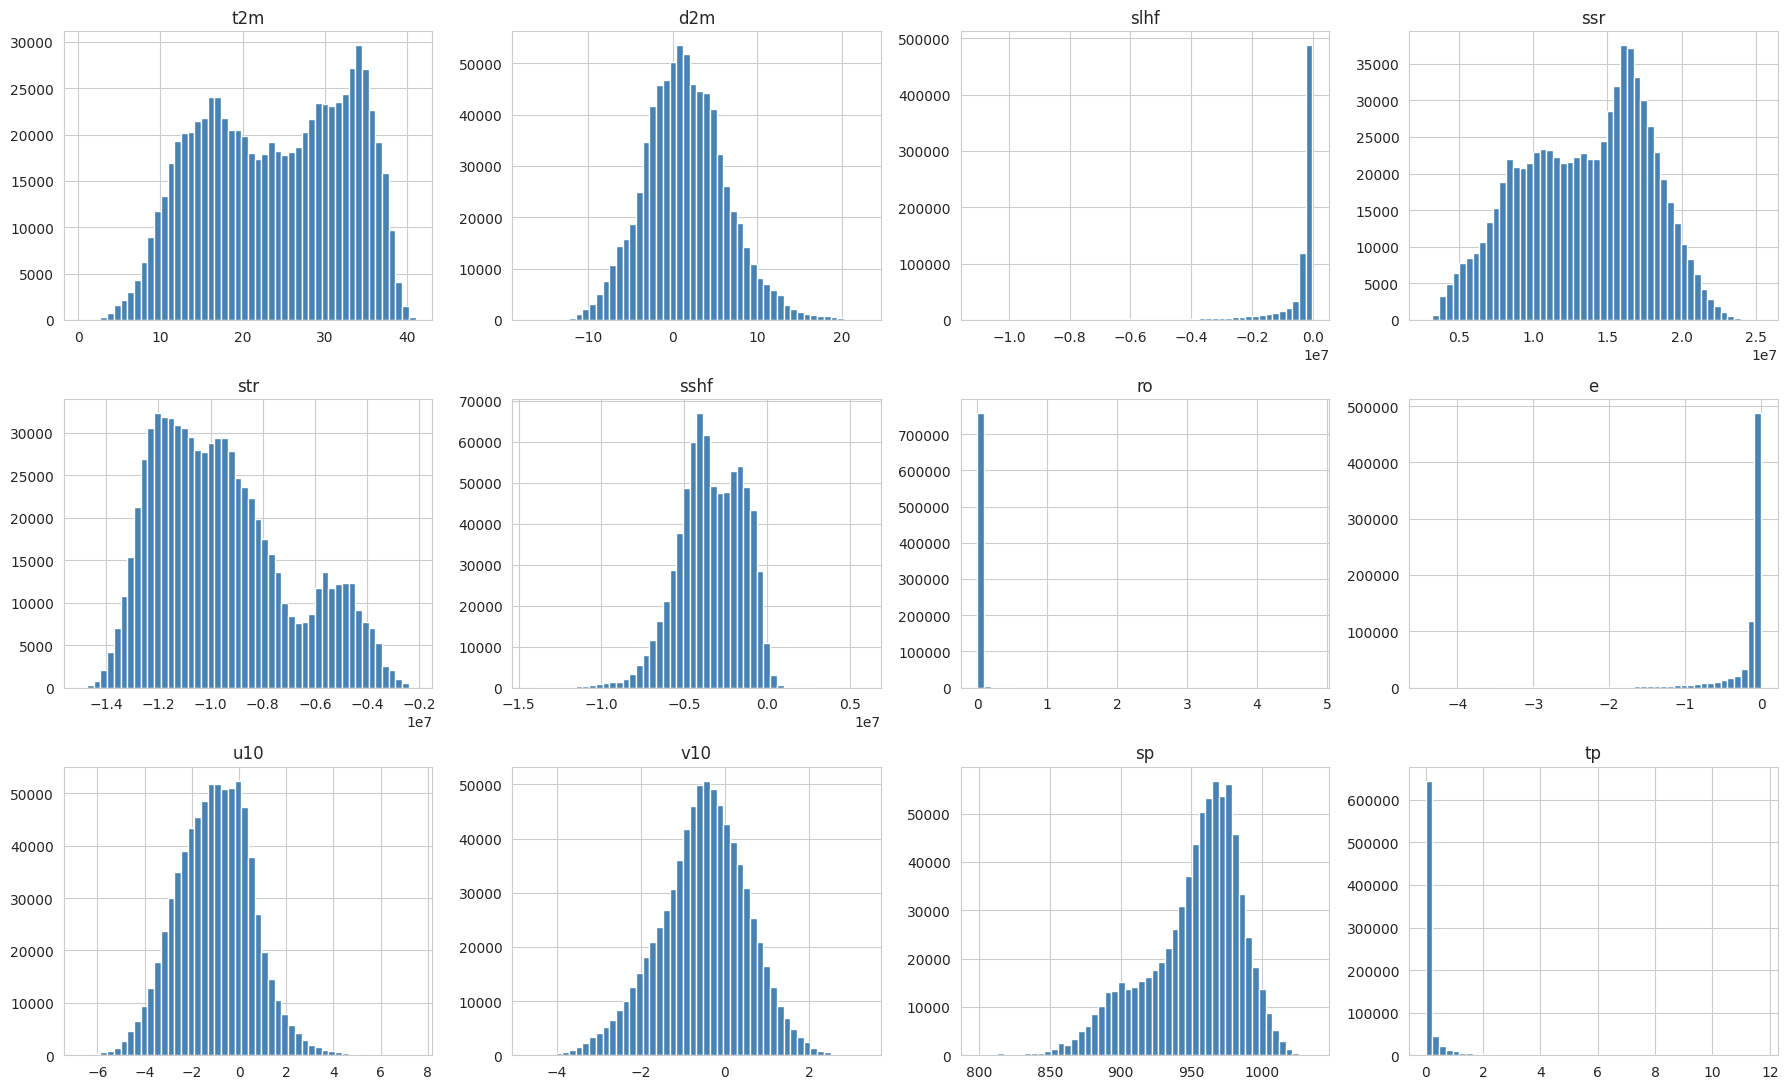

In [12]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, v in zip(axes.flat, VARS):
    ax.hist(df[v].dropna(), bins=50, color="steelblue", edgecolor="white")
    ax.set_title(v)
plt.tight_layout()
plt.show()

**Interprétation des histogrammes**

t2m a deux bosses, vers 17 °C et vers 34 °C, qui correspondent à l'hiver et à l'été. d2m a une forme de cloche centrée près de 1 à 2 °C avec une queue un peu plus longue vers les fortes valeurs. slhf est presque entièrement collée près de zéro avec une longue queue vers les valeurs très négatives. ssr est large avec un pic vers 16 millions qui reflète les saisons, et un côté gauche plus étalé qui vient des mois d'hiver et en partie de la période anormale 2022 à 2024 où ssr est divisé par deux. str a un pic vers moins 12 millions et une deuxième bosse vers moins 5 millions, qui vient en grande partie de cette période anormale (str y est divisé par deux, de −10 à −5 millions). sshf est une cloche avec un pic vers moins 4.5 millions et une petite bosse vers moins 1.5 million, probablement due à la même période. ro est presque toujours égale à zéro avec de très rares valeurs fortes. e a exactement la même forme que slhf, collée près de zéro avec une queue vers les valeurs négatives, car les deux variables sont quasi proportionnelles (flux de chaleur latente et évaporation). u10 est une cloche presque symétrique centrée autour de moins 1, v10 est une cloche presque symétrique centrée vers moins 0.5 avec une queue un peu plus longue du côté négatif. sp a un pic vers 965 hPa avec une queue vers les basses pressions des zones élevées, et tp est presque toujours proche de zéro avec très peu de fortes pluies.

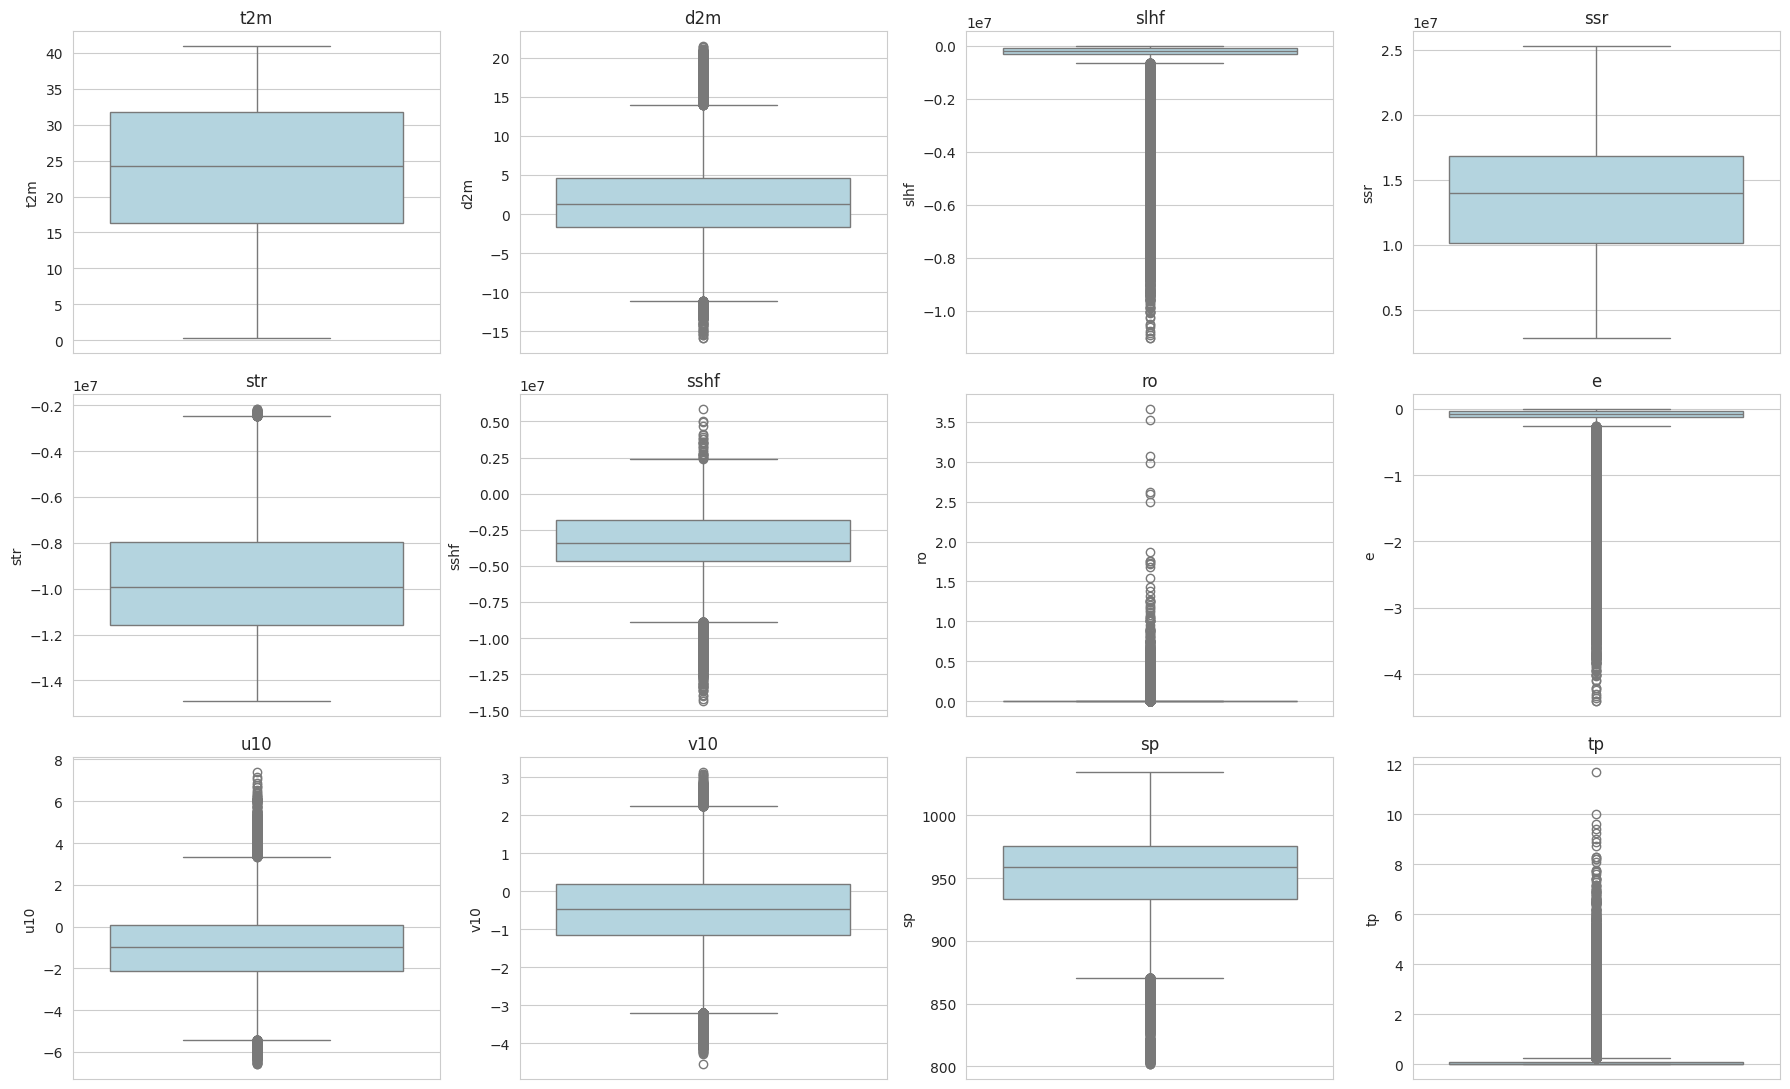

In [13]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, v in zip(axes.flat, VARS):
    sns.boxplot(y=echantillon[v], ax=ax, color="lightblue")
    ax.set_title(v)
plt.tight_layout()
plt.show()

**Interprétation des boxplots**

t2m a une boîte large avec la médiane au centre et aucun point aberrant, d2m a une boîte étroite autour de 1 avec des points aberrants des deux côtés, slhf et e ont une boîte écrasée près de zéro avec une longue colonne de points vers les valeurs négatives, ssr n'a aucun point aberrant et sa médiane est vers 14 millions, str a une boîte large avec seulement quelques points du côté des valeurs peu négatives, sshf a des points des deux côtés surtout vers le bas, ro a une boîte invisible car presque toutes les valeurs valent zéro avec quelques points isolés très élevés, u10 a des points des deux côtés un peu plus nombreux vers les valeurs positives, v10 a des points des deux côtés avec une médiane légèrement négative, sp a des points seulement vers le bas qui correspondent aux zones de haute altitude, et tp a une boîte écrasée avec une longue colonne de points et un cas extrême vers 12.

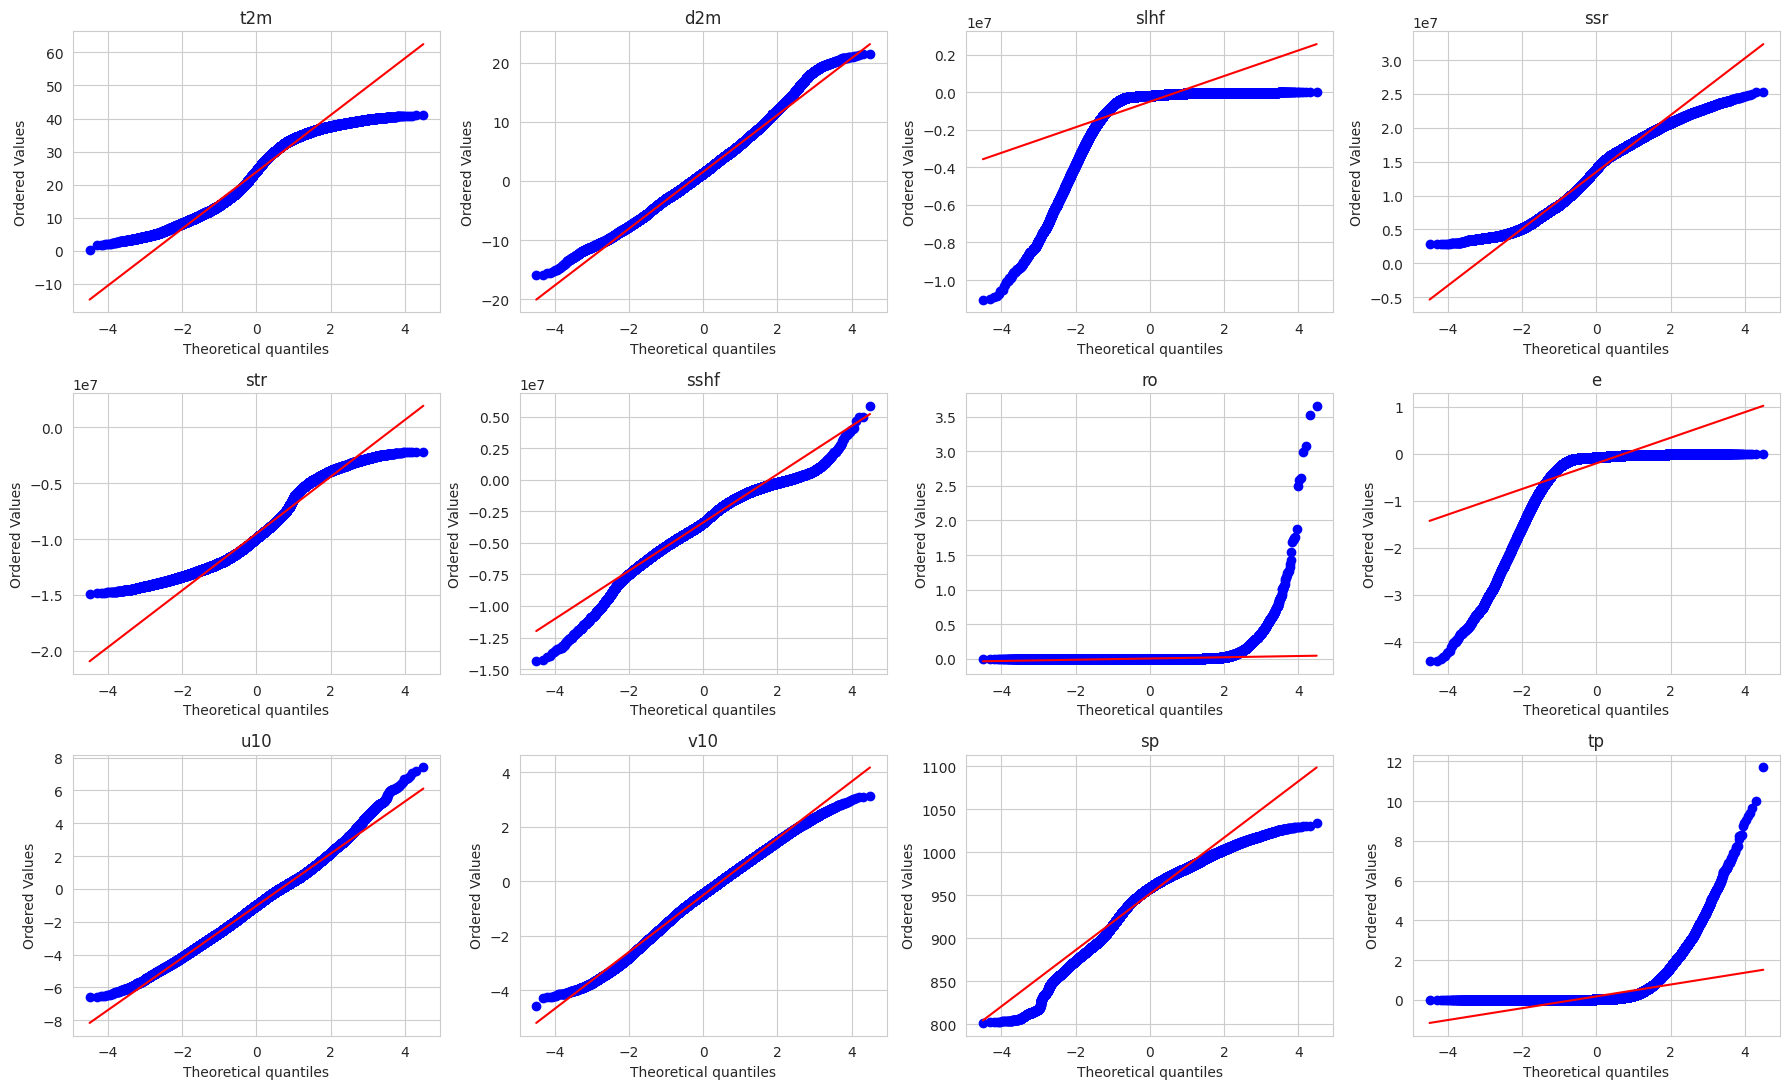

In [14]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, v in zip(axes.flat, VARS):
    stats.probplot(echantillon[v].dropna(), dist="norm", plot=ax)
    ax.set_title(v)
plt.tight_layout()
plt.show()

**Interprétation des Q-Q plots**

t2m forme un S car elle est plus aplatie qu'une loi normale à cause des deux saisons et de ses limites, d2m suit presque la droite donc elle est proche d'une loi normale avec de légères queues, slhf et e s'écartent très fortement de la droite (et sont identiques entre elles) donc elles sont très loin de la normalité. ssr et str forment un S léger avec des valeurs extrêmes moins étendues qu'une loi normale, sshf est proche de la droite au centre avec une légère ondulation et s'en écarte aux deux extrémités, surtout vers les valeurs très négatives. ro et tp restent à plat puis montent brutalement ce qui montre quelques valeurs énormes et donc une très forte asymétrie, u10 et v10 suivent presque la droite donc elles sont proches de la normale, et sp forme un S avec une queue vers les basses pressions des zones élevées. Ces écarts confirment que la normalité ne peut pas être supposée, ce qui justifie l'usage de la corrélation de Spearman et d'une mise à l'échelle robuste.

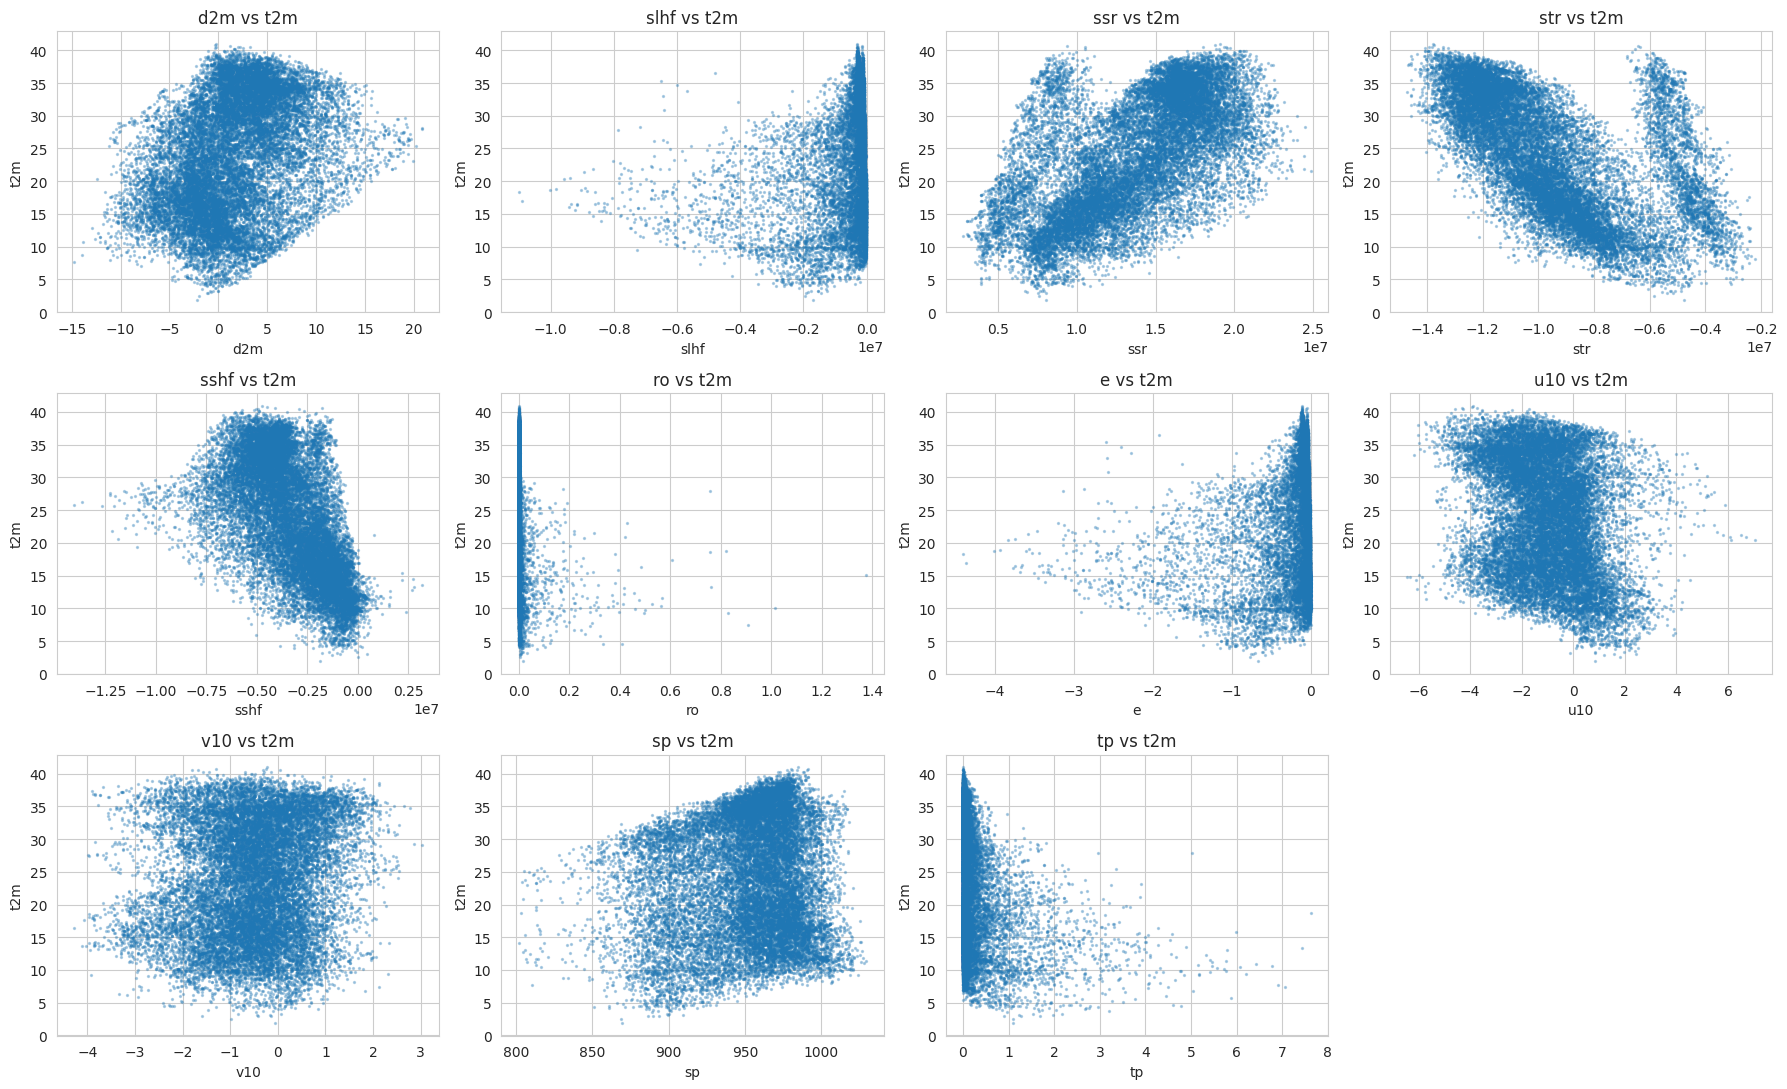

In [15]:
petit = echantillon.sample(
    n=min(20000, len(echantillon)),
    random_state=1
)

autres = [v for v in VARS if v != "t2m"]

fig, axes = plt.subplots(3, 4, figsize=(18, 11))

for ax, v in zip(axes.flat, autres):
    ax.scatter(petit[v], petit["t2m"], s=2, alpha=0.3)
    ax.set_xlabel(v)
    ax.set_ylabel("t2m")
    ax.set_title(f"{v} vs t2m")

axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

**Interprétation des nuages de points avec t2m**

ssr, str et sshf sont les variables les plus liées à la température (corrélations d'environ 0.6 en valeur absolue), ssr monte avec t2m alors que str et sshf descendent, mais les nuages sont larges, donc aucune variable ne suffit seule et il faudra les utiliser ensemble. Sur ssr et str, un groupe de points se détache du nuage principal, par exemple des mois très chauds (30 à 40 °C) avec très peu de soleil, ce qui n'est pas réaliste et correspond à la période anormale de septembre 2022 à février 2024 (diagnostiquée plus bas), il faudra donc corriger cette période avant de construire les données d'apprentissage.

slhf, e, ro et tp sont collées contre zéro avec quelques points très éloignés et ne montrent aucune relation linéaire avec t2m, on appliquera un log avant la mise à l'échelle (sur la valeur absolue pour slhf et e, qui sont négatives) pour étaler leurs valeurs. Les fortes pluies se voient surtout pour des températures modérées (environ 7 à 25 °C), ce qui correspond au nord et à l'hiver. d2m ne montre pas de relation nette avec t2m, le nuage forme deux paquets le long de l'axe de t2m, l'un vers 15 à 20 °C et l'autre vers 30 à 35 °C, qui correspondent à l'hiver et à l'été et reflètent la double bosse de t2m, ce qui montre qu'elle vient des saisons (voir section 7) et justifie de garder le mois comme variable. sp montre que les plus fortes températures n'apparaissent qu'à pression élevée, donc à basse altitude, le relief limite la chaleur, alors que u10 et v10 sont très dispersées et apportent peu d'information seules.

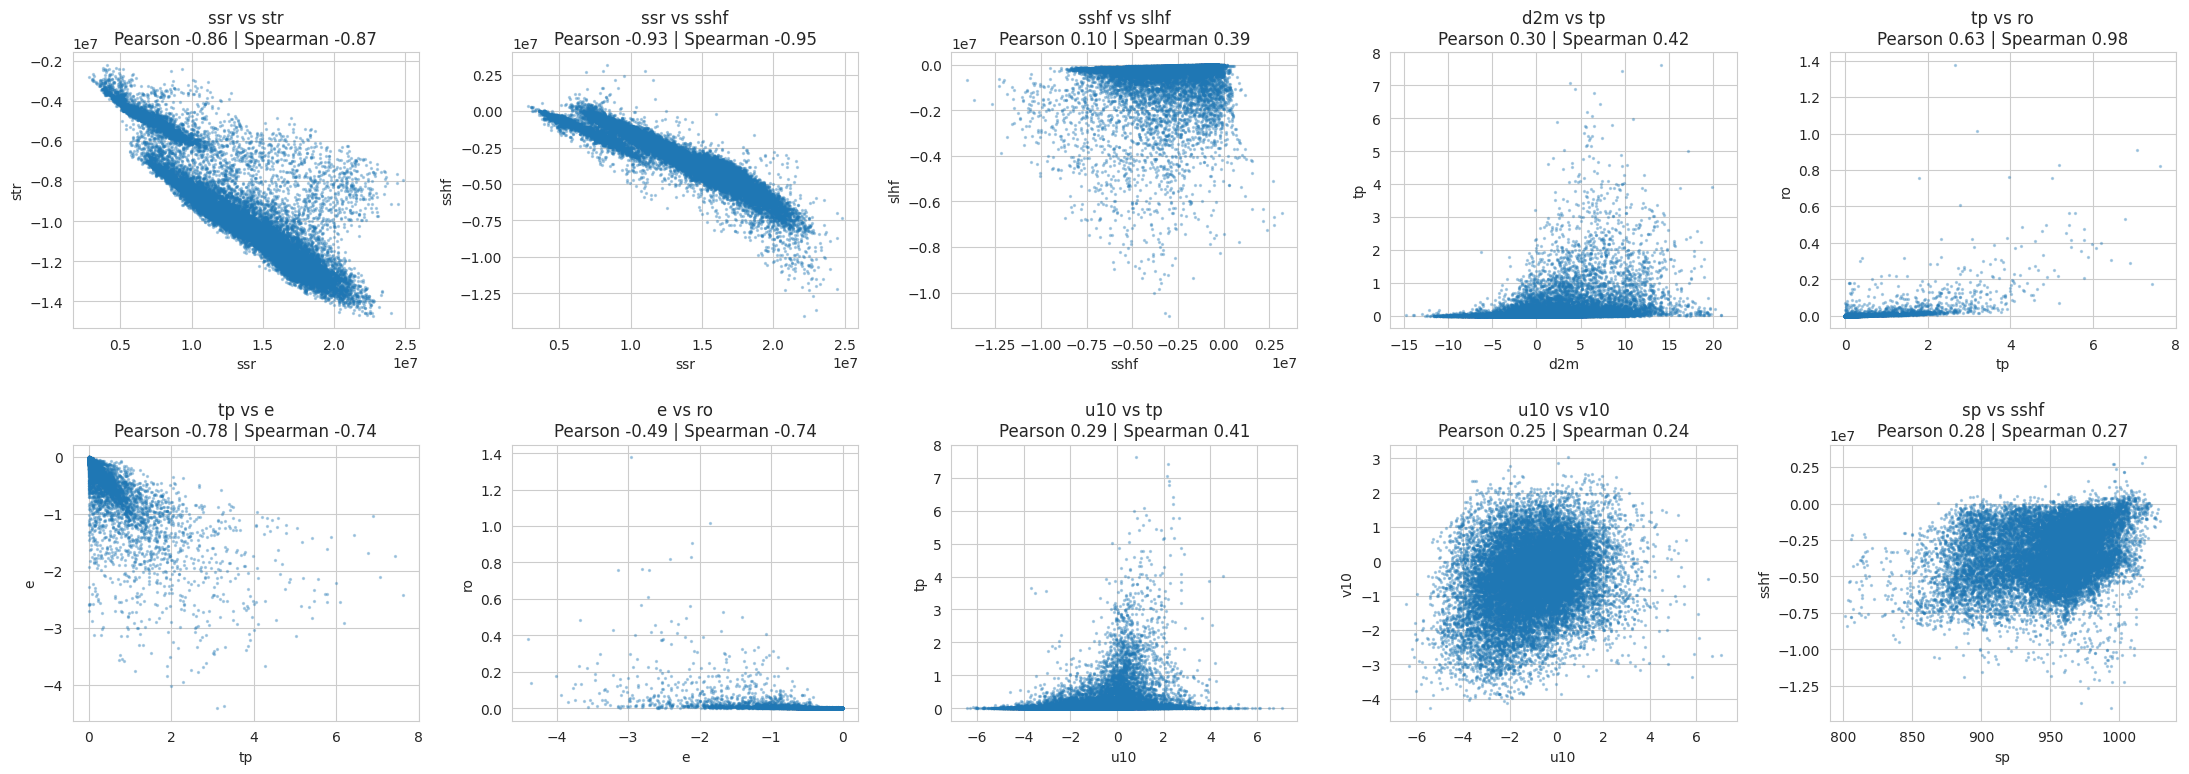

In [16]:
paires = [
    ("ssr", "str"), ("ssr", "sshf"), ("sshf", "slhf"), ("d2m", "tp"), ("tp", "ro"),
    ("tp", "e"), ("e", "ro"), ("u10", "tp"), ("u10", "v10"), ("sp", "sshf"),
]

fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, (a, b) in zip(axes.flat, paires):
    ax.scatter(petit[a], petit[b], s=2, alpha=0.3)
    rp = petit[a].corr(petit[b], method="pearson")
    rs = petit[a].corr(petit[b], method="spearman")
    ax.set_xlabel(a)
    ax.set_ylabel(b)
    ax.set_title(f"{a} vs {b}\nPearson {rp:.2f} | Spearman {rs:.2f}")
plt.tight_layout()
plt.show()

**Interprétation des nuages de points entre variables**

ssr forme des bandes presque droites avec str et sshf, leur corrélation est de −0.86 et −0.93 (Pearson), ces variables portent donc en grande partie la même information, on les gardera car le sujet les impose, mais il faudra tenir compte de cette redondance dans l'analyse des résultats. Sur ssr et str, on voit deux bandes parallèles, la seconde correspond à la période anormale 2022 à 2024 où str est moins négative pour un même ssr, ce qui confirme que ces mois sont incohérents avec le reste, la correction devra être faite avant la construction des features du clustering qui utilisent str.

Pour sshf et slhf, la surface chauffe surtout l'air, mais slhf devient très négatif dans une petite partie des cas, les zones et les mois humides où l'énergie sert à évaporer, ce qui explique un Pearson très faible (0.10) contre un Spearman nettement plus fort (0.39). d2m et tp montrent que les fortes pluies apparaissent surtout quand le point de rosée est positif et que tp reste quasi nulle quand il est négatif, un air humide est nécessaire mais ne suffit pas, la relation en entonnoir n'est pas une droite. tp et ro forment une relation en seuil, ro reste proche de zéro pour la plupart des pluies puis monte après un certain niveau, c'est monotone mais pas linéaire, d'où un Spearman à 0.98 contre un Pearson de 0.63, ces deux variables seront donc transformées par un log.

tp, e et ro décrivent le même phénomène, les zones humides du nord, ce qui devrait permettre de retrouver des zones géographiques lors du clustering. La corrélation négative entre tp et e (−0.78) ne signifie pas que la pluie réduit l'évaporation, elle vient de la convention de signe : e est négatif, donc plus il pleut, plus l'évaporation est grande en valeur absolue. Pour u10 et tp, la pluie se concentre autour de u10 proche de zéro ou positif, probablement quand le vent d'est faiblit ou tourne à l'ouest, la relation est en pic et non monotone, donc mal résumée par une corrélation (0.29 et 0.41). u10 et v10 forment un nuage rond sans direction privilégiée, leur corrélation est faible (environ 0.25), on garde donc les deux. sp et sshf ont un lien faible (0.28), sp reflète surtout l'altitude, c'est donc une information géographique plus qu'un échange de chaleur.

## 6. Valeurs aberrantes (IQR et Z-score)

In [17]:
lignes = []
for v in VARS:
    x = df[v].dropna()
    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1
    nb_iqr = ((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum()
    z = (x - x.mean()) / x.std()
    nb_z = (z.abs() > 3).sum()
    lignes.append([v, nb_iqr, nb_iqr / len(x) * 100, nb_z, nb_z / len(x) * 100])

aberrantes = pd.DataFrame(lignes, columns=["variable", "nb_IQR", "pct_IQR", "nb_Z", "pct_Z"])
aberrantes.round(2)

,variable,nb_IQR,pct_IQR,nb_Z,pct_Z
0,t2m,0,0.00,0,0.00
1,d2m,8600,1.12,3880,0.51
2,slhf,125715,16.43,21726,2.84
3,ssr,0,0.00,0,0.00
4,str,303,0.04,0,0.00
5,sshf,5865,0.77,4842,0.63
6,ro,123932,16.20,5519,0.72
7,e,125715,16.43,21726,2.84
8,u10,5546,0.73,3136,0.41
9,v10,8167,1.07,1672,0.22


**Interprétation**

t2m et ssr n'ont aucune valeur aberrante et str presque aucune (0.04 pour cent). d2m, sshf, u10, v10 et sp en ont peu (moins de 2 pour cent selon l'IQR), ce qui correspond à leurs formes proches d'une cloche, les points bas de sp viennent des zones de haute altitude. À l'inverse slhf, e, ro et tp en ont beaucoup selon la règle de l'IQR, environ 15 à 16 pour cent. Ce n'est pas un défaut : cette règle détecte trop de valeurs quand la distribution est très asymétrique, et pour ro l'IQR vaut pratiquement zéro (Q1 et Q3 sont presque nuls), donc la moindre valeur non négligeable est signalée. Ces valeurs correspondent à de vrais événements comme les fortes pluies ou la forte évaporation du nord, donc on ne les supprime pas et on utilise une mise à l'échelle robuste.

Le Z-score signale beaucoup moins de valeurs que l'IQR pour ces variables (environ 2.4 à 2.8 pour cent pour slhf, e et tp, 0.7 pour cent pour ro), car la moyenne et l'écart-type sont eux-mêmes gonflés par les valeurs extrêmes. Les deux critères ne sont donc pas fiables pour des variables aussi asymétriques, ce qui renforce le choix de ne rien supprimer. slhf et e ont exactement les mêmes décomptes, une preuve de plus qu'elles sont redondantes.

## 7. Analyse temporelle

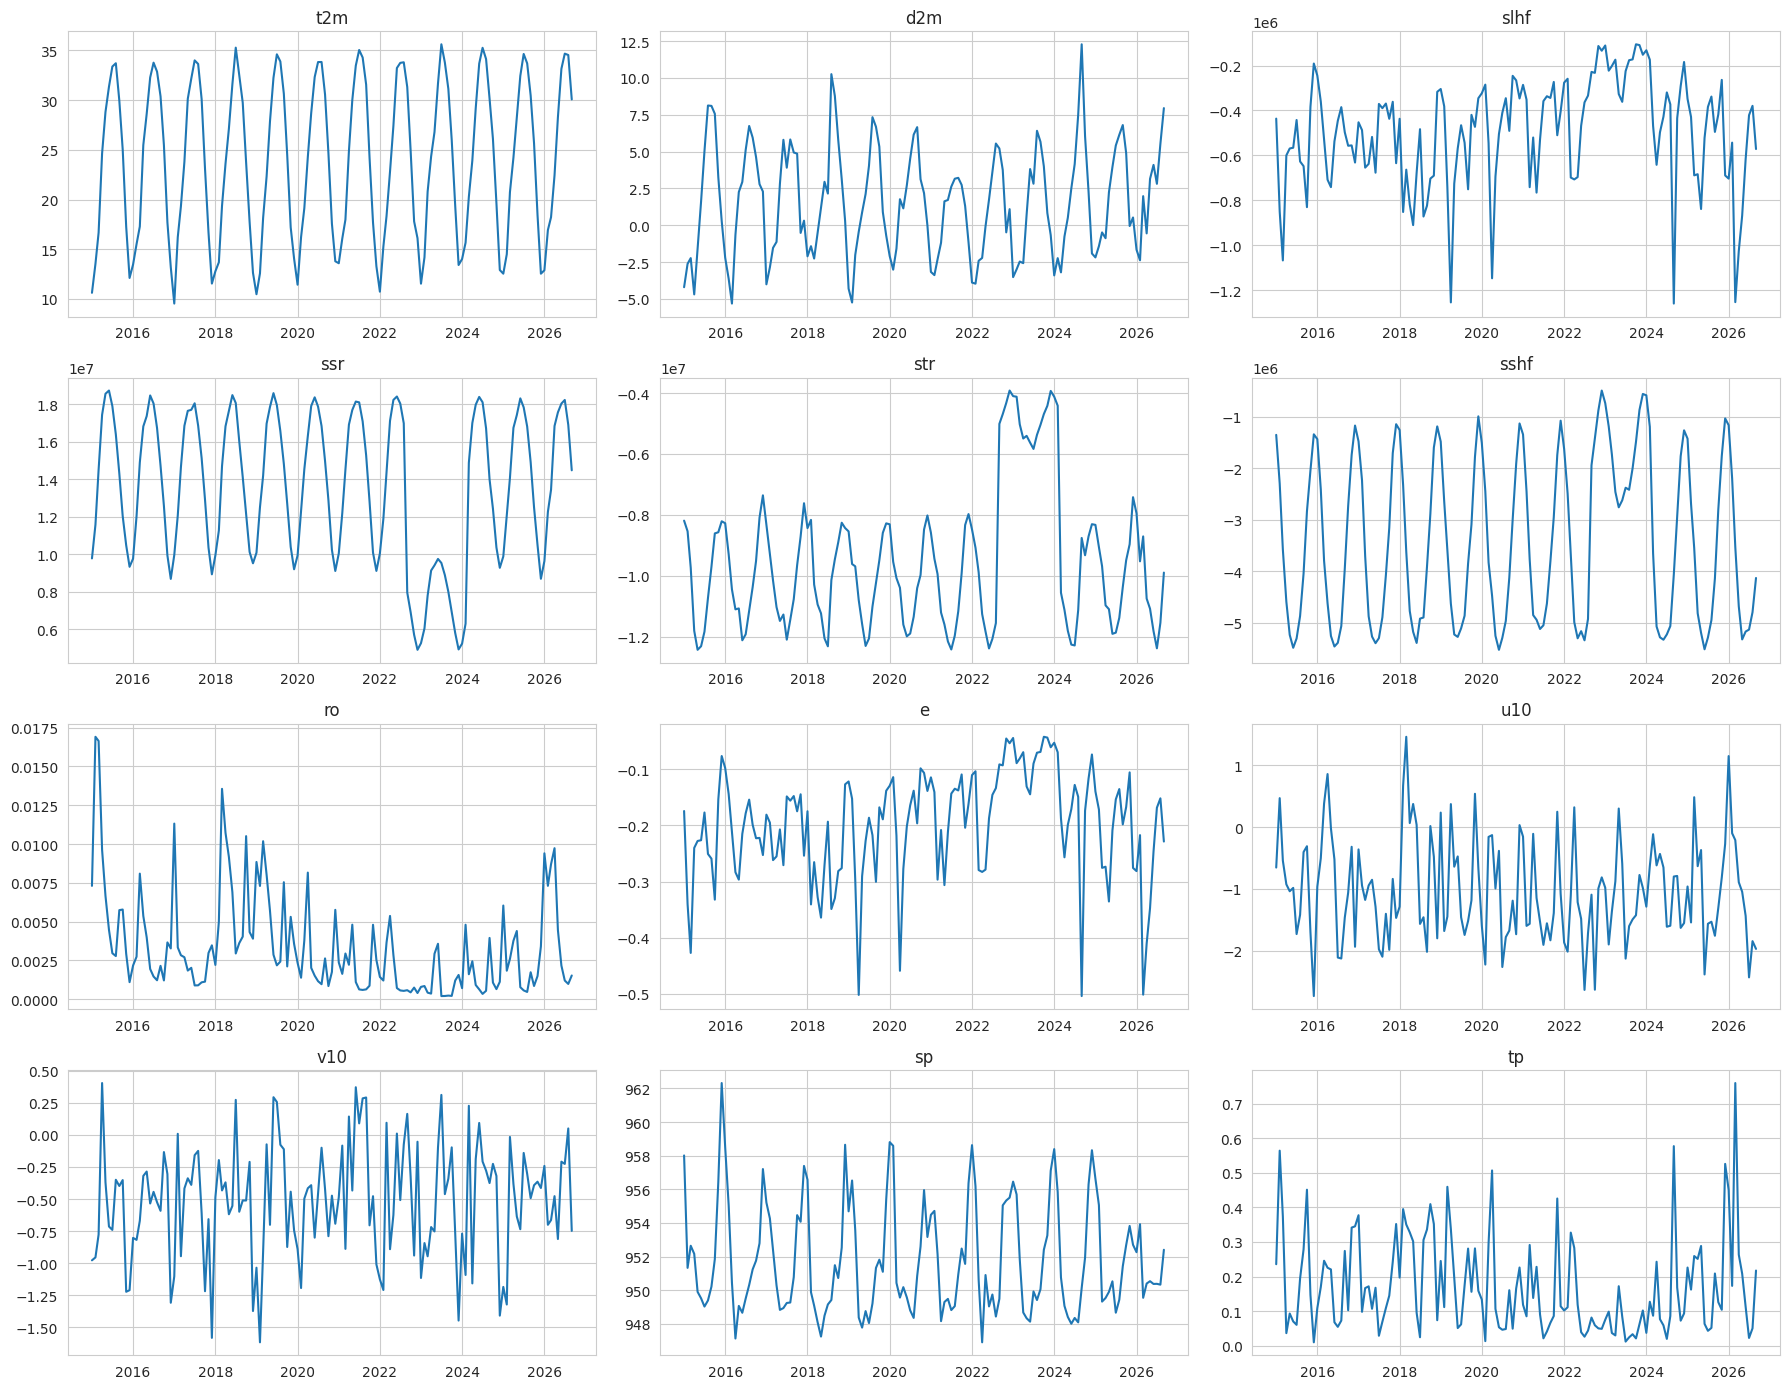

In [18]:
serie = df.groupby("time")[VARS].mean()

fig, axes = plt.subplots(4, 3, figsize=(18, 14))
for ax, v in zip(axes.flat, VARS):
    ax.plot(serie.index, serie[v])
    ax.set_title(v)
plt.tight_layout()
plt.show()

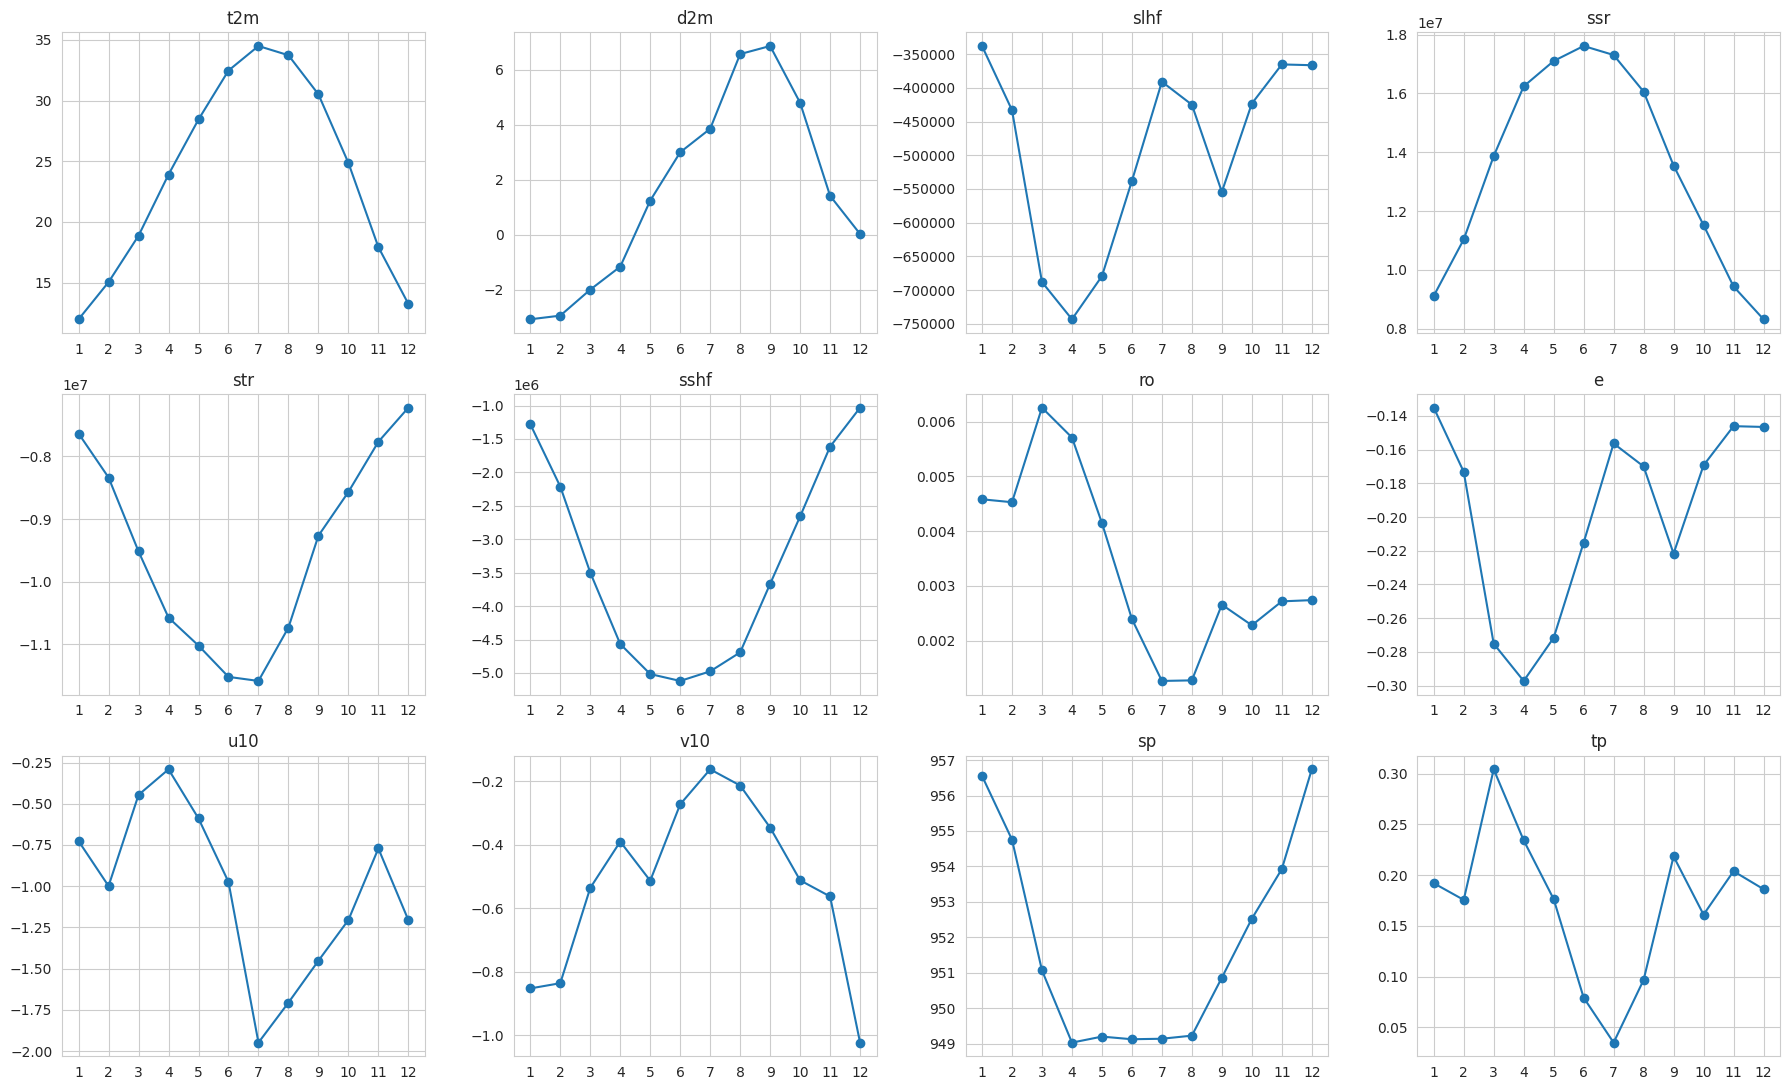

In [19]:
saison = df.groupby("month")[VARS].mean()

fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, v in zip(axes.flat, VARS):
    ax.plot(saison.index, saison[v], marker="o")
    ax.set_xticks(range(1, 13))
    ax.set_title(v)
plt.tight_layout()
plt.show()

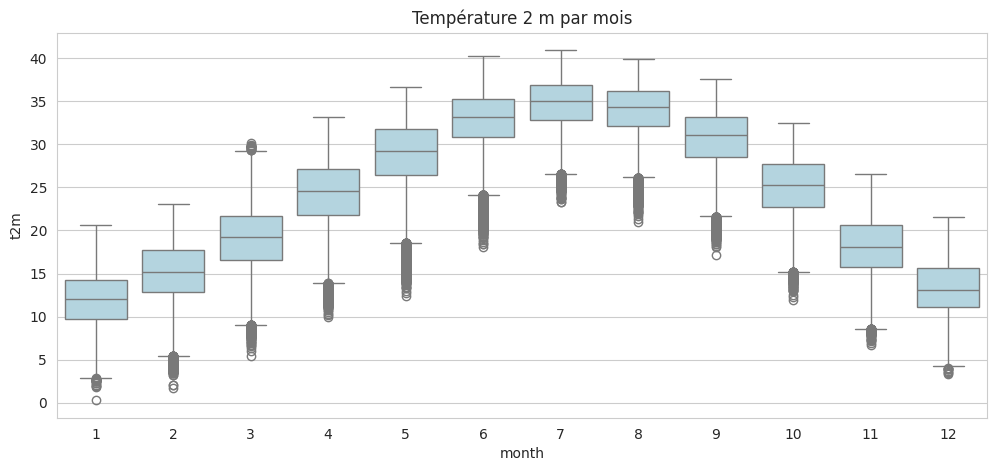

In [20]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=echantillon, x="month", y="t2m", color="lightblue")
plt.title("Température 2 m par mois")
plt.show()

**Interprétation de l'analyse temporelle et de la saisonnalité**

Les séries de la moyenne sur l'Algérie montrent pour t2m une oscillation régulière entre environ 10 et 35 °C avec une amplitude stable d'une année à l'autre, la tendance éventuelle est très faible devant ce cycle et invisible à l'œil. Sur ssr, str et sshf on voit nettement la rupture de septembre 2022 à février 2024 (ssr tombe vers 5 à 9 millions, str et sshf deviennent beaucoup moins négatifs) puis le retour à la normale, alors que slhf et e s'affaiblissent seulement sur la période sans rupture nette. ro, tp, u10 et v10 sont irrégulières sans cycle évident à cette échelle, avec par exemple un pic de ro au début de 2015 (environ cinq fois sa moyenne) qui correspond à un événement pluvieux.

Le cycle moyen par mois montre que t2m est la plus basse en janvier (environ 12 °C) et la plus haute en juillet (environ 34.5 °C). ssr culmine en juin et est minimale en décembre, str et sshf sont les plus négatifs en été (mai à juillet pour sshf) car le sol chaud perd le plus d'énergie. d2m est minimal en janvier et février (environ −3 °C) et maximal en août et septembre (environ 7 °C), il suit donc la chaleur avec un décalage d'un à deux mois. tp et ro sont maximales en mars et minimales en été (tp est presque nulle en juillet), slhf et e sont les plus négatifs au printemps (mars à avril) puis ont un second creux en septembre, ce qui correspond au retour des pluies, l'évaporation est donc limitée en été par le manque d'eau et non par la chaleur. sp est basse d'avril à août (environ 949 hPa) et haute en hiver (environ 957 hPa), ce qui est cohérent avec la dépression thermique d'été. u10 est le plus négatif en juillet (vent d'est plus fort) et v10 est le moins négatif en juillet. Ces courbes incluent les 18 mois anormaux, elles sous-estiment donc légèrement l'amplitude saisonnière de ssr, str et sshf.

Les boîtes de t2m par mois montrent que la médiane passe de 12 °C en janvier à 35 °C en juillet, et que l'étalement à l'intérieur d'un mois (boîte d'environ 4 à 6 °C) est bien plus faible que l'étalement global (IQR de 15 °C), donc le mois explique une grande partie de la variance de t2m, ce qui confirme qu'il faut le garder comme variable. Avril et octobre ont des médianes presque identiques (environ 24.5 et 25 °C), la température seule ne distingue donc pas le printemps de l'automne et le mois est nécessaire pour lever l'ambiguïté. Les points isolés sous les boîtes de l'été viennent des cellules de montagne (Hoggar, Atlas), plus fraîches que le désert.

In [21]:
annees_completes = mois_par_annee[mois_par_annee == 12].index
annuel = df[df["year"].isin(annees_completes)].groupby("year")[VARS].mean()
annuel.round(2)

,t2m,d2m,slhf,ssr,str,sshf,ro,e,u10,v10,sp,tp
year,,,,,,,,,,,,
2015,23.090000,1.55,-601042.562500,14246044.0,-10056160.0,-3578397.50,0.01,-0.24,-1.00,-0.64,952.739990,0.21
2016,23.840000,1.74,-516337.375000,14164893.0,-10059345.0,-3582641.50,0.00,-0.21,-0.81,-0.56,951.809998,0.19
2017,23.360001,1.53,-499225.093750,14252899.0,-10150963.0,-3599896.25,0.00,-0.20,-1.28,-0.63,952.099976,0.17
2018,23.320000,2.36,-687504.750000,14066657.0,-9885283.0,-3492519.25,0.01,-0.27,-0.50,-0.47,950.950012,0.26
2019,23.209999,1.22,-581354.000000,14312431.0,-10183492.0,-3540623.25,0.01,-0.23,-0.80,-0.50,951.390015,0.21
2020,23.870001,1.80,-467125.968750,14264323.0,-10169493.0,-3618950.50,0.00,-0.19,-1.17,-0.59,952.239990,0.15
2021,24.350000,0.43,-451786.468750,14326076.0,-10391799.0,-3474501.00,0.00,-0.18,-1.13,-0.24,951.460022,0.14
2022,23.799999,0.66,-375942.312500,12537157.0,-8707239.0,-3184580.75,0.00,-0.15,-1.44,-0.46,952.150024,0.11
2023,24.059999,1.00,-194834.984375,7609099.0,-4922760.5,-1763602.25,0.00,-0.08,-1.15,-0.61,951.780029,0.06


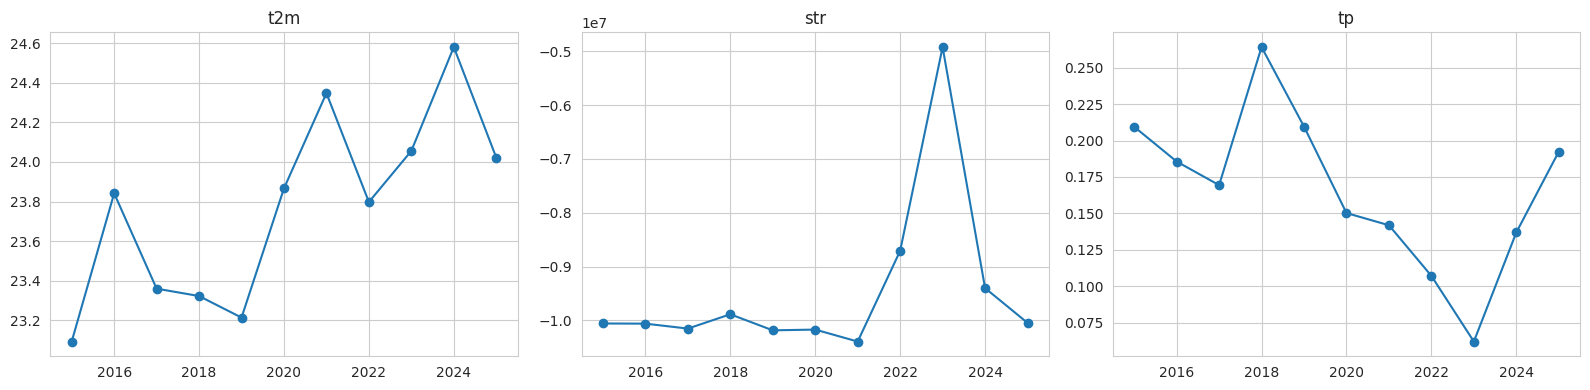

Pente de t2m par an : 0.1071 °C/an
p-value : 0.0089


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, v in zip(axes, ["t2m", "str", "tp"]):
    ax.plot(annuel.index, annuel[v], marker="o")
    ax.set_title(v)
plt.tight_layout()
plt.show()

reg = stats.linregress(annuel.index, annuel["t2m"])
print("Pente de t2m par an :", round(reg.slope, 4), "°C/an")
print("p-value :", round(reg.pvalue, 4))

### Diagnostic de l'anomalie d'acquisition (ssr, str, sshf, puis vérification pour slhf, e, tp, ro)

Ratio mensuel entre la valeur observée et la climatologie du mois (calculée sur les années hors 2022-2024), pour repérer les mois touchés et vérifier si le facteur est stable.

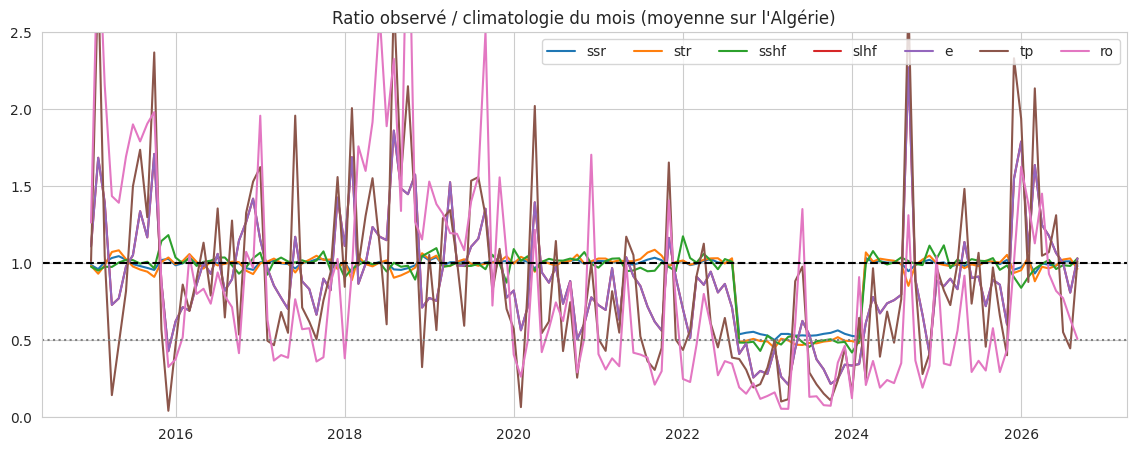

Variabilité normale du ratio (années de référence) :
      ssr   str  sshf  slhf     e    tp    ro
min  0.93  0.88  0.84  0.43  0.43  0.04  0.21
max  1.05  1.09  1.18  1.86  1.86  2.87  3.60

Ratio autour de la période suspecte :
             ssr   str  sshf  slhf     e    tp    ro
time                                                
2022-08-01  1.02  1.03  1.01  0.71  0.71  0.39  0.35
2022-09-01  0.54  0.49  0.48  0.41  0.41  0.38  0.19
2022-10-01  0.55  0.50  0.48  0.48  0.48  0.31  0.15
2022-11-01  0.56  0.51  0.49  0.26  0.26  0.19  0.22
2022-12-01  0.54  0.50  0.43  0.30  0.30  0.22  0.12
2023-01-01  0.53  0.49  0.53  0.28  0.28  0.32  0.14
2023-02-01  0.50  0.45  0.49  0.44  0.44  0.50  0.16
2023-03-01  0.54  0.51  0.47  0.26  0.26  0.10  0.06
2023-04-01  0.54  0.50  0.52  0.21  0.21  0.12  0.05
2023-05-01  0.53  0.47  0.53  0.44  0.44  0.88  0.61
2023-06-01  0.53  0.47  0.49  0.63  0.63  0.98  1.35
2023-07-01  0.53  0.48  0.46  0.53  0.53  0.29  0.13
2023-08-01  0.53  0.48  0.49

In [23]:
# Ratio observé / climatologie du mois (moyenne sur l'Algérie)
ACC = ["ssr", "str", "sshf", "slhf", "e", "tp", "ro"]   # variables accumulées

moy_mensuelle = df.groupby("time")[ACC].mean()

# Climatologie calculée sur des années de référence (hors 2022-2024)
ref = moy_mensuelle[~moy_mensuelle.index.year.isin([2022, 2023, 2024])]
clim_mois = ref.groupby(ref.index.month).mean()

ratio = moy_mensuelle / clim_mois.loc[moy_mensuelle.index.month].values

fig, ax = plt.subplots(figsize=(14, 5))
for v in ACC:
    ax.plot(ratio.index, ratio[v], label=v)
ax.axhline(1, color="k", ls="--")
ax.axhline(0.5, color="gray", ls=":")
ax.set_ylim(0, 2.5)
ax.set_title("Ratio observé / climatologie du mois (moyenne sur l'Algérie)")
ax.legend(ncol=7)
plt.show()

print("Variabilité normale du ratio (années de référence) :")
print(ratio.loc[ref.index].agg(["min", "max"]).round(2))
print("\nRatio autour de la période suspecte :")
print(ratio.loc["2022-08":"2024-04"].round(2))

In [24]:
# Mois suspects : ssr, str et sshf toutes sous 75 % de leur climatologie (seuil à ajuster selon la cellule précédente)
suspect = (ratio[["ssr", "str", "sshf"]] < 0.75).all(axis=1)
mois_suspects = ratio.index[suspect]

print("Premier mois :", mois_suspects.min().date())
print("Dernier mois :", mois_suspects.max().date())
print("Nombre de mois :", len(mois_suspects))
print("Période continue :", suspect.loc[mois_suspects.min():mois_suspects.max()].all())

print("\nRatio dans la période suspecte (stable autour d'une valeur ?) :")
print(ratio.loc[mois_suspects, ACC].describe().round(2))

Premier mois : 2022-09-01
Dernier mois : 2024-02-01
Nombre de mois : 18
Période continue : True

Ratio dans la période suspecte (stable autour d'une valeur ?) :
         ssr    str   sshf   slhf      e     tp     ro
count  18.00  18.00  18.00  18.00  18.00  18.00  18.00
mean    0.54   0.49   0.49   0.36   0.36   0.35   0.30
std     0.01   0.02   0.03   0.11   0.11   0.26   0.35
min     0.50   0.45   0.42   0.21   0.21   0.10   0.05
25%     0.53   0.48   0.48   0.27   0.27   0.17   0.12
50%     0.54   0.49   0.49   0.34   0.34   0.27   0.15
75%     0.54   0.50   0.50   0.43   0.43   0.43   0.32
max     0.56   0.52   0.53   0.63   0.63   0.98   1.35


**Interprétation**

Le cycle saisonnier est très net et se répète chaque année, chaud en été et frais en hiver. La température annuelle moyenne passe de 23.09 °C en 2015 (la plus basse) à 24.58 °C en 2024 (la plus haute), puis redescend à 24.02 °C en 2025. La droite de régression donne +0.107 °C par an avec une p-value de 0.009 inférieure à 0.05, soit environ 1 °C en dix ans, mais cette tendance repose sur seulement 11 points annuels, elle est portée par les années récentes (2020 à 2024) et elle est plus rapide que les tendances de long terme habituellement rapportées pour la région, elle décrit donc la période 2015-2025 et ne doit pas être extrapolée. La p-value est indicative car des années successives ne sont pas indépendantes. Dans le tableau annuel, le point de rosée, la pression et les vents ne montrent pas de tendance claire.

Le diagnostic de l'anomalie montre que de septembre 2022 à février 2024, soit 18 mois consécutifs, ssr, str et sshf tombent d'un coup à environ la moitié de leur climatologie (ratios moyens de 0.54, 0.49 et 0.49 avec un écart-type de 0.01 à 0.03, alors que leur variabilité normale reste entre 0.84 et 1.18), puis reviennent à leur niveau normal dès mars 2024. Un facteur quasi constant pendant 18 mois, qui touche à la fois le rayonnement solaire, le rayonnement thermique et la chaleur sensible, n'a aucune explication climatique, c'est donc très probablement un défaut de la source des données et non un phénomène réel. Il fausse aussi les moyennes annuelles de 2022 à 2024 (par exemple ssr annuel de 7.6 millions en 2023 contre environ 14.2 millions les autres années), qui ne doivent pas être utilisées telles quelles.

Pour slhf et e, les ratios sont aussi bas pendant la période (0.36 en moyenne), mais leur variabilité normale est bien plus large (0.43 à 1.86) et les ratios ne sont pas stables (écart-type 0.11), l'effet est donc moins net et ne se prête pas à une correction par un facteur unique. Pour tp et ro, les ratios restent dans leur plage normale de variation (tp de 0.04 à 2.87), la faible pluie de 2023 peut donc être réelle (sécheresse) et rien ne prouve qu'elles soient touchées. t2m ne montre aucune rupture, la tendance ci-dessus n'est donc pas affectée. L'anomalie sera corrigée dans le prétraitement.

## 8. Analyse spatiale

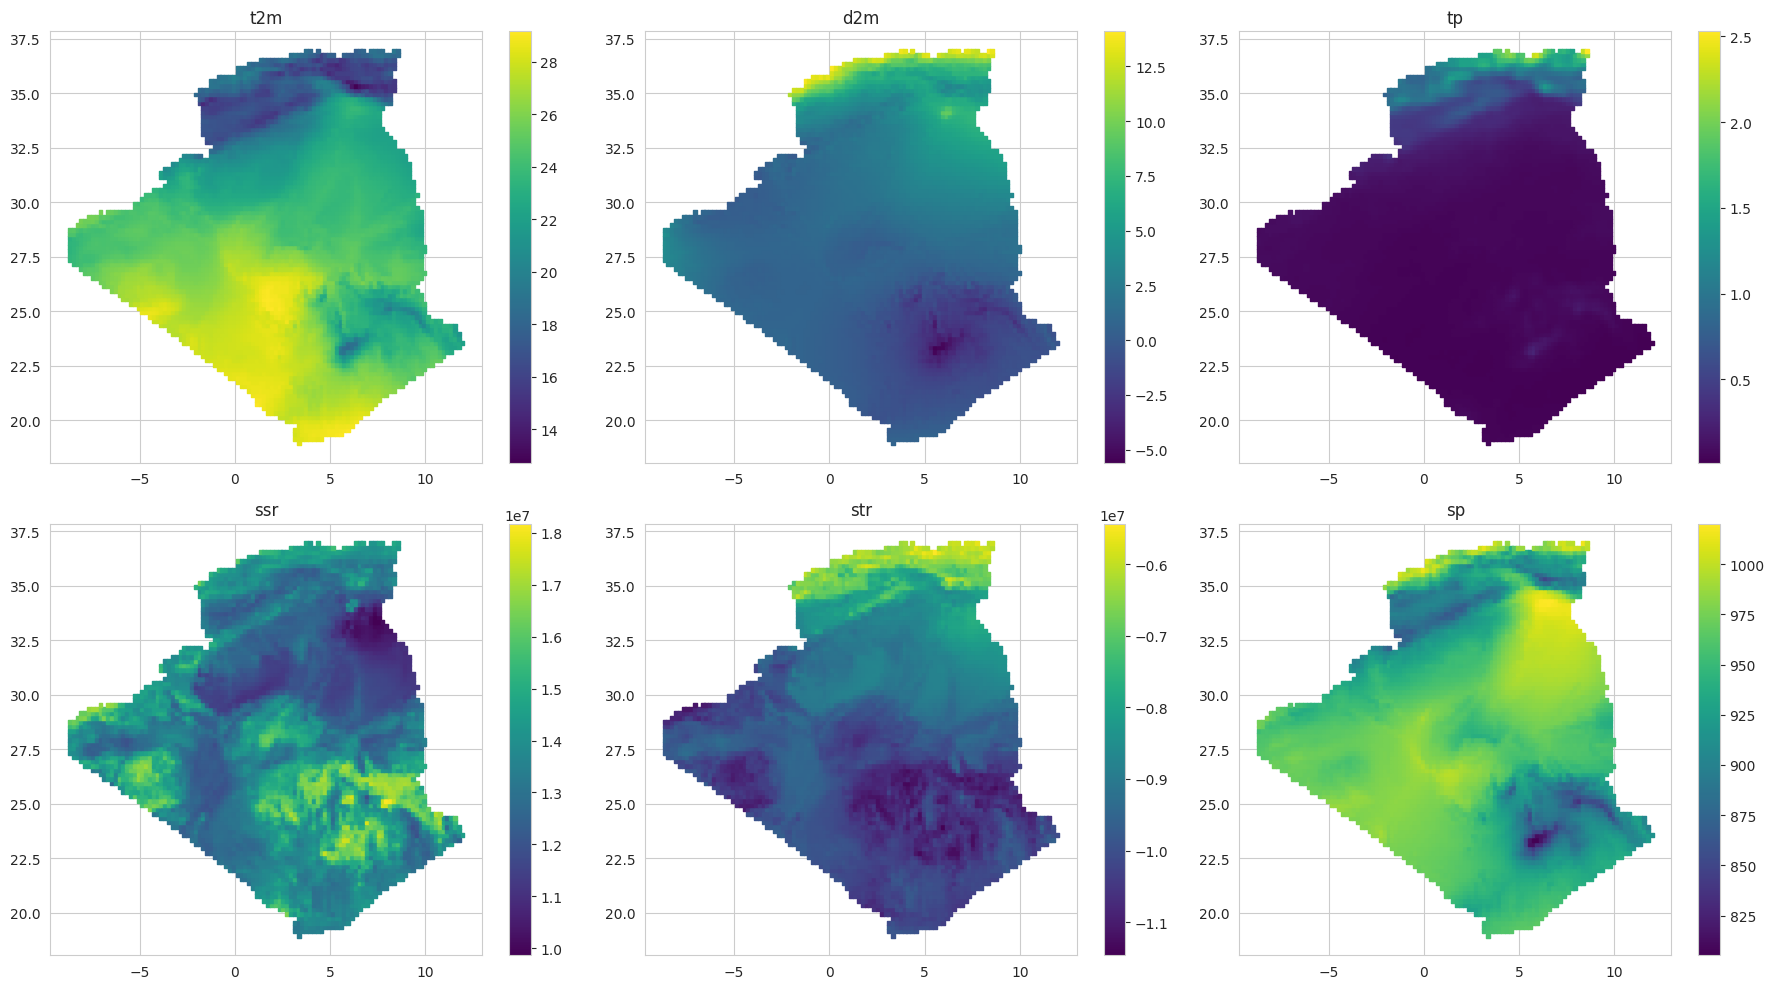

In [25]:
carte = df.groupby(["cell_id", "latitude", "longitude"])[VARS].mean().reset_index()

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, v in zip(axes.flat, ["t2m", "d2m", "tp", "ssr", "str", "sp"]):
    sc = ax.scatter(carte["longitude"], carte["latitude"], c=carte[v], cmap="viridis", s=8, marker="s")
    plt.colorbar(sc, ax=ax)
    ax.set_title(v)
plt.tight_layout()
plt.show()

In [26]:
df.groupby("region", observed=True)[["t2m", "d2m", "tp", "ssr", "str", "sp"]].mean().round(2)

,t2m,d2m,tp,ssr,str,sp
region,,,,,,
Sud,26.24,-0.73,0.04,14191912.0,-10337577.0,940.299988
Centre,24.15,1.63,0.08,13157587.0,-9604310.0,964.239990
Nord,18.18,6.06,0.74,13154888.0,-7495443.0,937.919983


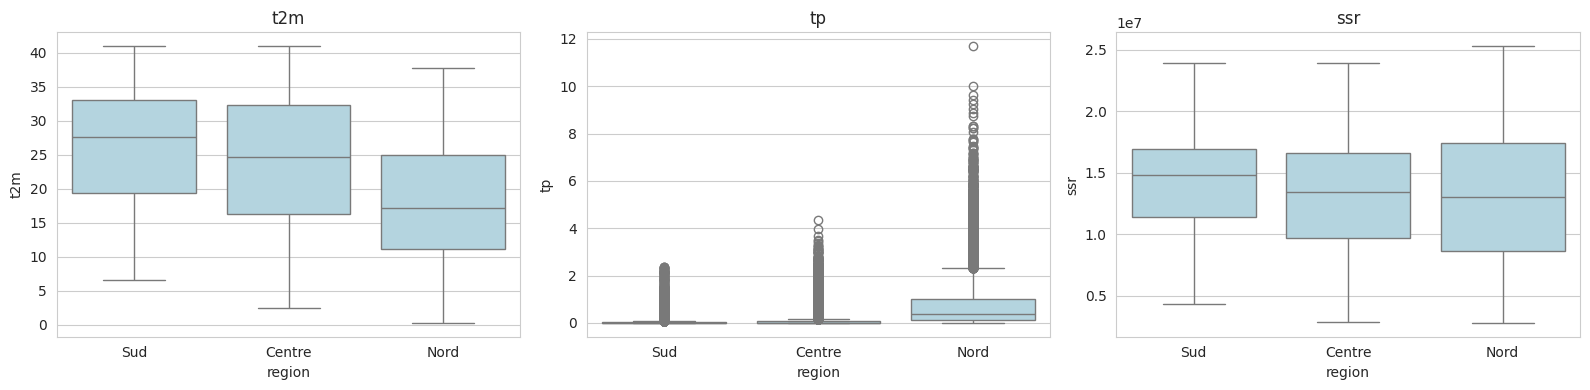

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, v in zip(axes, ["t2m", "tp", "ssr"]):
    sns.boxplot(data=echantillon, x="region", y=v, ax=ax, color="lightblue")
    ax.set_title(v)
plt.tight_layout()
plt.show()

**Interprétation de l'analyse spatiale**

Les cartes montrent une organisation géographique nette. t2m est la plus élevée dans le Sahara du centre et de l'ouest (environ 28 à 29 °C en moyenne) et la plus basse au nord (moins de 20 °C) et dans le massif du Hoggar, où l'altitude refroidit l'air. La carte de sp le confirme, la pression y descend vers 810 hPa, c'est-à-dire une altitude de plusieurs milliers de mètres, et elle est élevée dans les zones basses, par exemple près de la dépression des chotts à l'est (vers 34°N, 6°E), sp reflète donc le relief et non la météo. d2m et tp ne sont élevés que sur la bande côtière et les reliefs du nord (tp au-dessus de 0.5 mm par jour seulement dans cette bande, jusqu'à 2.5), le reste du pays reçoit presque aucune pluie. str est moins négative au nord (air plus humide et plus nuageux qui renvoie du rayonnement thermique vers le sol) et plus négative dans le désert (air sec). ssr varie moins clairement et de façon irrégulière, avec les plus fortes valeurs dans le centre-sud et le sud-est (Hoggar et Tassili), car il dépend aussi du relief et de la nébulosité, ce n'est pas un simple gradient nord-sud. Ces moyennes incluent les mois anormaux de ssr et str, ce qui diminue leurs niveaux sans changer l'organisation spatiale (le facteur est le même partout).

Le tableau par région confirme ces contrastes : t2m vaut 26.2 °C au Sud, 24.2 au Centre et 18.2 au Nord, d2m passe de −0.7 à 1.6 puis 6.1 °C, et tp est environ 18 fois plus forte au Nord (0.74) qu'au Sud (0.04). ssr ne diffère que de 8 pour cent entre le Sud (14.2 millions) et les deux autres régions (13.2 millions), str est nettement moins négative au Nord (−7.5 contre −10.3 millions au Sud), et sp n'est pas monotone avec la latitude (964 hPa au Centre, 940 au Sud, 938 au Nord) car le Sud contient le Hoggar et le Nord l'Atlas, c'est encore l'altitude. Les boîtes montrent que les distributions de t2m se chevauchent largement entre régions (la saison domine), donc la région seule ne prédit pas la classe de température, alors que tp et le couple d2m, str séparent clairement le Nord. ssr a la boîte la plus large au Nord, ce qui traduit un contraste d'ensoleillement plus fort entre hiver et été aux latitudes élevées. Ces résultats annoncent que le clustering retrouvera surtout un gradient nord-sud, avec le Nord (peu de cellules) bien distinct, et un effet d'altitude pour le Hoggar.

## 9. Corrélations

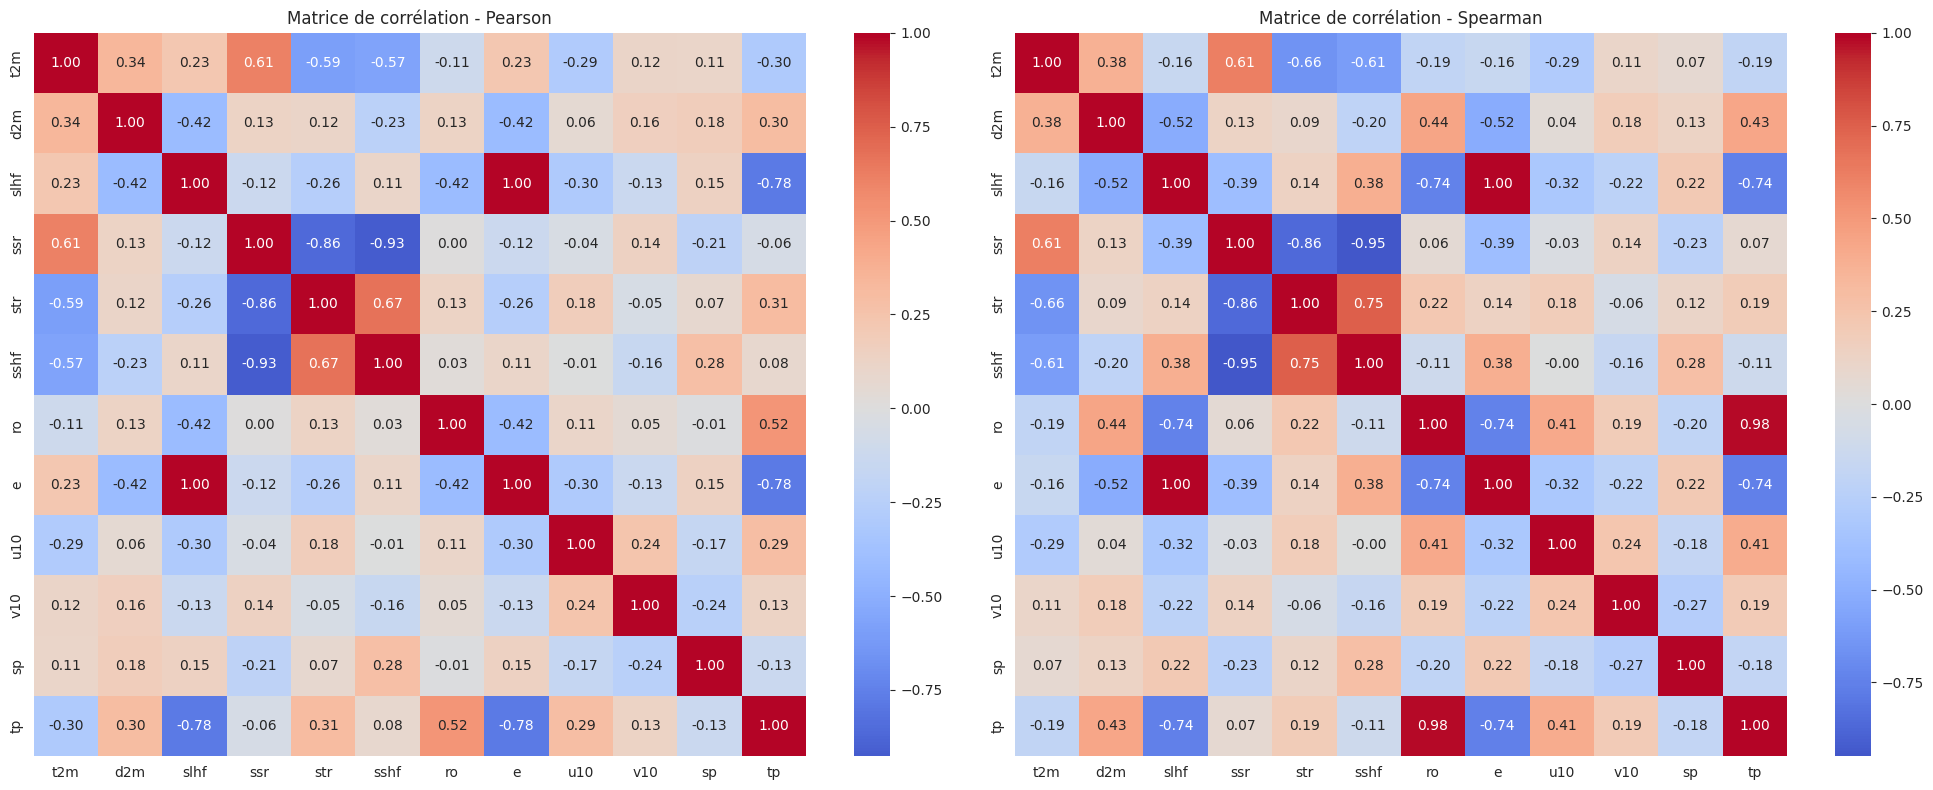

In [28]:
# Sélection des variables
VARS = [
    "t2m", "d2m", "slhf", "ssr", "str",
    "sshf", "ro", "e", "u10", "v10",
    "sp", "tp"
]

# Création d'un seul échantillon commun
echantillon = df[VARS].sample(
    n=200_000,
    random_state=42
)

# Calcul des deux matrices de corrélation sur le même échantillon
corr_pearson = echantillon.corr(method="pearson")
corr_spearman = echantillon.corr(method="spearman")

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

sns.heatmap(
    corr_pearson,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    ax=axes[0]
)
axes[0].set_title("Matrice de corrélation - Pearson")

sns.heatmap(
    corr_spearman,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    ax=axes[1]
)
axes[1].set_title("Matrice de corrélation - Spearman")

plt.tight_layout()
plt.show()

**Interprétation des matrices de corrélation**

t2m est liée surtout à ssr (+0.61 en Pearson et en Spearman), str (−0.59 et −0.66) et sshf (−0.57 et −0.61), puis plus faiblement à d2m (+0.34 et +0.38) et u10 (−0.29). Aucune corrélation avec t2m ne dépasse 0.66, donc aucune variable ne suffit seule, ce qui est cohérent avec les nuages de points. Pour slhf et e, la corrélation avec t2m change de signe entre Pearson (+0.23) et Spearman (−0.16), il n'y a donc pas de relation monotone fiable.

ssr, str et sshf sont très liées entre elles (ssr et sshf −0.93 et −0.95, ssr et str −0.86, str et sshf +0.67 et +0.75), ce trio est fortement colinéaire, ce qui gêne les modèles sensibles à la redondance comme KNN et SVM (les distances comptent deux ou trois fois la même information) alors que Random Forest la supporte mieux. slhf et e ont une corrélation de 1.00 : ce sont la même information à une constante près, il faut s'attendre à ce qu'elles soient interchangeables dans les modèles.

Les écarts entre Pearson et Spearman sont grands pour ro, tp, slhf et e (par exemple tp et ro : 0.52 contre 0.98) car ces variables sont très asymétriques et leur lien est monotone mais non linéaire, Spearman est donc plus fiable pour elles. tp est liée à slhf et e (−0.78 et −0.74), le signe négatif venant de la convention de signe de l'évaporation, et d2m est liée positivement à tp (0.30 et 0.43) et négativement à e (−0.42 et −0.52) : un air humide va avec plus de pluie et plus d'évaporation. u10 est modérément liée à tp et ro (0.29 à 0.41), v10 et sp sont faiblement liées à tout (au plus 0.28), sp apporte donc surtout de l'information géographique. Ces corrélations sont calculées sur un échantillon de 200000 lignes qui inclut la période anormale, elles seront à recalculer après correction.

## 10. Cible et classes

Seuils : [ 0.28 13.86 27.44 41.03]
t2m
Froid      0.159
Tempéré    0.435
Chaud      0.406
Name: proportion, dtype: float64


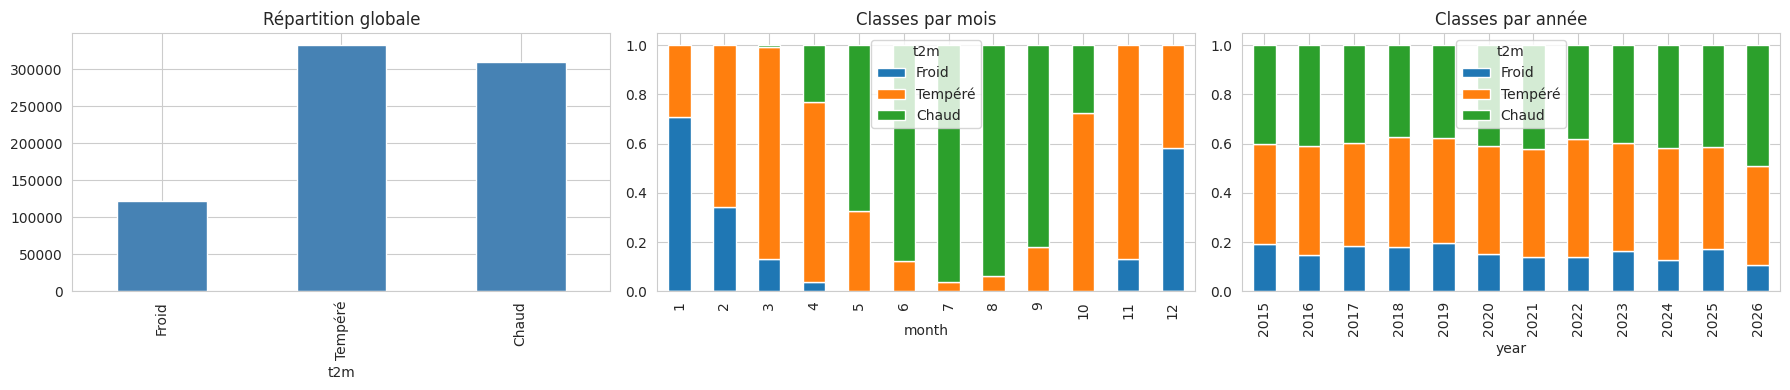

In [29]:
# Seuils : 3 intervalles de largeur égale sur la plage de t2m (exploration, sur toutes les données)
t_min, t_max = float(df["t2m"].min()), float(df["t2m"].max())
seuils = np.linspace(t_min, t_max, 4)
noms = ["Froid", "Tempéré", "Chaud"]
print("Seuils :", seuils.round(2))

classe = pd.cut(df["t2m"], bins=seuils, labels=noms, include_lowest=True)
print(classe.value_counts(normalize=True).sort_index().round(3))

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
classe.value_counts().sort_index().plot.bar(ax=axes[0], color="steelblue")
axes[0].set_title("Répartition globale")

pd.crosstab(df["month"], classe, normalize="index").plot.bar(stacked=True, ax=axes[1])
axes[1].set_title("Classes par mois")

pd.crosstab(df["year"], classe, normalize="index").plot.bar(stacked=True, ax=axes[2])
axes[2].set_title("Classes par année")
plt.tight_layout()
plt.show()

**Interprétation de la cible et des classes**

Les seuils à largeur égale sont 13.86 et 27.44 °C (largeur d'environ 13.6 °C sur la plage de 0.28 à 41.03 °C), ce qui donne Froid (moins de 13.86 °C) 15.9 pour cent, Tempéré 43.5 pour cent et Chaud (plus de 27.44 °C) 40.6 pour cent. Les classes sont déséquilibrées : Froid est minoritaire, il faudra donc suivre le F1 macro et le rappel par classe en plus de l'accuracy, qui seule favorise les classes Tempéré et Chaud. Les bornes extrêmes de la plage viennent de quelques cellules-mois, elles déterminent donc les seuils plus que la masse des données. Ici les seuils sont calculés sur toutes les données pour l'exploration, dans l'apprentissage ils devront l'être sur le jeu d'entraînement seul pour éviter une fuite d'information.

La classe dépend très fortement du mois : en janvier environ 70 pour cent des lignes sont Froid et le reste Tempéré, en juillet environ 96 pour cent sont Chaud, Froid n'existe qu'entre novembre et avril et Chaud est quasi absent de janvier à mars. Les mois de transition (mars à mai et octobre à décembre) sont ceux où la classe du mois suivant est la plus incertaine. Par année, la répartition est assez stable (Froid entre 13 et 20 pour cent, Chaud autour de 40 pour cent), avec une légère baisse de Froid sur 2015-2025 cohérente avec le réchauffement. La barre de 2026 (Chaud environ 49 pour cent, Froid environ 11 pour cent) est trompeuse : l'année n'a que neuf mois et il manque octobre à décembre, mois frais, donc elle ne doit pas être interprétée comme un signe de réchauffement.

## 11. Persistance et saisonnalité

In [30]:
d = df.sort_values(["cell_id", "time"]).copy()
d["t2m_next"] = d.groupby("cell_id")["t2m"].shift(-1)   # 141 mois consécutifs par cellule
d = d.dropna(subset=["t2m_next"])
d["month_next"] = d["month"] % 12 + 1

# Climatologie cellule x mois (pour le mois courant et le mois suivant)
d["clim"] = d.groupby(["cell_id", "month"])["t2m"].transform("mean")
d["clim_next"] = d.groupby(["cell_id", "month_next"])["t2m_next"].transform("mean")

def r2(y, pred):
    return 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()

print("Corr t2m(t) vs t2m(t+1) :", round(d["t2m"].corr(d["t2m_next"]), 3))
print("R2 persistance (prédire t+1 par t) :", round(r2(d["t2m_next"], d["t2m"]), 3))
print("R2 climatologie (cellule x mois)   :", round(r2(d["t2m_next"], d["clim_next"]), 3))

# Persistance des anomalies (écart à la climatologie)
a = d["t2m"] - d["clim"]
a_next = d["t2m_next"] - d["clim_next"]
print("Corr des anomalies (t, t+1) :", round(a.corr(a_next), 3))

# Baselines en classes
cls = lambda x: pd.cut(x, bins=seuils, labels=False, include_lowest=True)
y = cls(d["t2m_next"])
print("\nAccuracy classe majoritaire :", round(y.value_counts(normalize=True).max(), 3))
print("Accuracy persistance        :", round((cls(d["t2m"]) == y).mean(), 3))
print("Accuracy climatologie       :", round((cls(d["clim_next"]) == y).mean(), 3))

Corr t2m(t) vs t2m(t+1) : 0.868
R2 persistance (prédire t+1 par t) : 0.733
R2 climatologie (cellule x mois)   : 0.98
Corr des anomalies (t, t+1) : 0.158

Accuracy classe majoritaire : 0.437
Accuracy persistance        : 0.718
Accuracy climatologie       : 0.931


**Interprétation de la persistance et de la saisonnalité**

La corrélation entre t2m au mois t et au mois t+1 est de 0.868, mais prédire le mois suivant par le mois courant ne donne qu'un R² de 0.733 : la température change beaucoup d'un mois à l'autre à cause du cycle saisonnier. À l'inverse, la climatologie par cellule et par mois explique 98 pour cent de la variance (R² de 0.98), donc quasiment toute la variabilité de t2m vient du lieu et de la saison. La corrélation des anomalies (écart à la climatologie) entre t et t+1 n'est que de 0.158 (environ 2.5 pour cent de variance expliquée), une fois la saison retirée le mois courant dit très peu de choses sur le mois suivant.

En classes, la classe majoritaire donne 43.7 pour cent d'accuracy, la persistance 71.8 pour cent et la climatologie 93.1 pour cent. Les modèles supervisés devront donc se comparer à ces références et il faut s'attendre à un gain maximal limité au-delà de 93 pour cent. Cette climatologie est un plafond optimiste car elle est calculée sur toutes les années (y compris celles qui serviront de test) et elle utilise l'identité de la cellule, qui n'est pas dans la liste de features de l'énoncé (les variables comme sp, d2m ou str ne peuvent la remplacer qu'en partie). De même, la persistance utilise t2m du mois courant, qui n'est pas non plus dans la liste de features de l'énoncé, c'est donc une référence et non un modèle concurrent. Le mois comme feature est essentiel, il porte l'essentiel du signal, et le test chronologique mesure surtout la capacité des modèles à retrouver ce cycle.

## 12. Aperçu pour le clustering

Attention : la pente de `str` inclut les années touchées par l'anomalie, elle n'est pas interprétable avant correction.

Cellules avec tendance t2m > 0 : 100.0 %
       pente_t2m   pente_str
count   5425.000    5425.000
mean       0.107  186653.799
std        0.029   33142.795
min        0.031   80817.452
25%        0.088  173383.241
50%        0.103  197330.150
75%        0.119  209643.177
max        0.211  244927.914


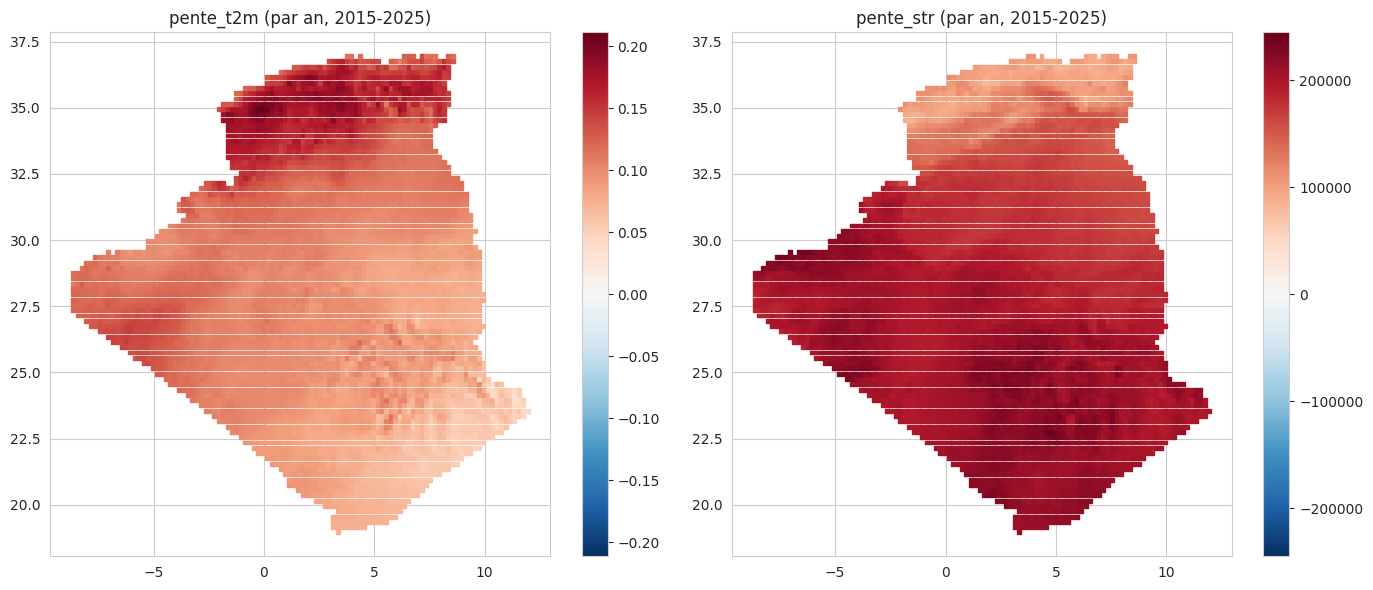

In [31]:
yrs = np.array(sorted(annees_completes))
x = yrs - yrs.mean()

an = df[df["year"].isin(yrs)].groupby(["cell_id", "year"])[["t2m", "str"]].mean().reset_index()
coord = df.drop_duplicates("cell_id").set_index("cell_id")[["latitude", "longitude"]]

def pentes(v):
    M = an.pivot(index="cell_id", columns="year", values=v)
    p = (M.values - M.values.mean(axis=1, keepdims=True)) @ x / (x ** 2).sum()
    return pd.Series(p, index=M.index)

pente = pd.DataFrame({"pente_t2m": pentes("t2m"), "pente_str": pentes("str")})
pente = pente.join(coord)

print("Cellules avec tendance t2m > 0 :", round((pente["pente_t2m"] > 0).mean() * 100, 1), "%")
print(pente[["pente_t2m", "pente_str"]].describe().round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, v in zip(axes, ["pente_t2m", "pente_str"]):
    m = np.abs(pente[v]).max()
    sc = ax.scatter(pente["longitude"], pente["latitude"], c=pente[v],
                    cmap="RdBu_r", vmin=-m, vmax=m, s=8, marker="s")
    plt.colorbar(sc, ax=ax)
    ax.set_title(f"{v} (par an, 2015-2025)")
plt.tight_layout()
plt.show()

**Interprétation des pentes par cellule**

La pente de t2m est positive dans 100 pour cent des cellules, avec une moyenne de 0.107 °C par an (de 0.03 à 0.21, écart-type 0.029), cohérente avec la pente nationale. Elle n'est pas uniforme : elle est la plus forte au nord (autour de 0.15 à 0.2 °C par an, entre 34 et 36°N) et la plus faible dans le sud-est (Hoggar et Tassili, environ 0.05), la tendance a donc une structure spatiale, ce qui en fait un bon candidat pour distinguer des groupes dans le clustering. Elle reste calculée sur 11 ans seulement, sans correction, et reflète en partie la variabilité interannuelle (2015 plus frais, 2021 et 2024 plus chauds).

La pente de str est positive partout (moyenne d'environ 187000 J/m² par an), mais elle n'est pas interprétable : elle vient de l'anomalie de 2022 à 2024, durant laquelle str est moins négative en fin de période, et non d'un vrai changement de rayonnement. Son motif spatial (plus faible au nord) ne doit donc pas être interprété physiquement, et cette variable devra être recalculée après correction avant d'être utilisée dans les features de clustering.